# 06. Model 2 — CatBoost: Leakage-Free Nested Evaluation and Employee Prediction
## Member 2 headline model · IT25100565

**Notebook:** `notebooks/team_contributions/models/member_2_catboost/06_m2_catboost.ipynb`
**Preprocessing input:** `notebooks/team_contributions/preprocessing/IT25100565_Preprocessing.ipynb` → `data/processed/catboost/`
**Group inputs:** `configs/feature_contract.yaml`, `data/processed/split_registry.csv`, `results/baselines/`
**Evidence:** `results/models/catboost/` (registered in `configs/analysis_registry.yaml`)
**Serialized model:** `models/catboost/` (git-ignored, like every model in this repository)

Everything about the model is in this one notebook. No external `.py` training script is used and no external notebook is required.

### Problem
Predict whether an employee will resign (`Resigned = 1`) from the 17 contract predictors. This is **binary classification** with a 10% positive class.

### Run modes (group convention)
| Switch | Default | Meaning |
| :--- | :--- | :--- |
| `RUN_CATBOOST_TRAINING` | `False` | **Saved review:** loads the completed evidence and never trains or writes files. `True` retrains everything (about 25–35 min) into a new `reruns/<UTC timestamp>/` folder; the canonical evidence is unchanged until that run is explicitly adopted. |
| `EVALUATE_HOLDOUT` | `False` | The group's 20% formal holdout stays **locked** until the final freeze; all results here are development cross-validation. |
| `RUN_TERMINAL_INPUT` | `True` | Asks for an employee's details at `input()` prompts in Section 13. |

### Workflow
| Section | What happens |
| :--- | :--- |
| 1–4 | Setup, paths, verified inputs, frozen split |
| 5 | Model choice and the leakage-free 5-fold CV engine |
| 6 | **Stage A:** four preprocessing varieties |
| 7 | **Stage B:** randomized hyperparameter search (25 + 1 configurations) |
| 8 | Selected configuration: fold metrics and learning curve |
| 9 | **Strict nested CV:** unbiased out-of-fold estimate used by the group comparison |
| 10 | Comparison with `DummyClassifier(prior)` and `DummyClassifier(most_frequent)` |
| 11 | Feature importance |
| 12 | Final model (refit on all development rows), plus the locked-holdout gate |
| 13 | Manual employee input and prediction: terminal prompts, form, dictionary |
| 14 | Conclusion, limitations and improvements |

## 1. Setup

In [4]:
# ------------------------------------------------------------
# RUN-MODE SWITCHES, IMPORTS AND GLOBAL SETTINGS
# ------------------------------------------------------------
# Run-mode switches (see the table above)
RUN_CATBOOST_TRAINING = False   # False = saved review (read-only); True = retrain into a new reruns/<UTC> folder
EVALUATE_HOLDOUT = False        # group rule: the formal holdout stays locked until the final freeze
RUN_TERMINAL_INPUT = True       # set False to skip the input() prompts when using "Run All"

# Import standard-library tools for paths, fingerprints, JSON, timing and version info
from pathlib import Path
import hashlib
import json
import sys
import time
import platform
from datetime import datetime, timezone

# Import analytical, visualization, configuration and statistical-testing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats
from IPython.display import display, Markdown

# Import scikit-learn: data splitting, the random search sampler, Dummy baselines and all metrics
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, ParameterSampler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, log_loss, brier_score_loss,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    accuracy_score, confusion_matrix, precision_recall_curve, roc_curve,
)

# Import the probability distributions used to sample hyperparameters
from scipy.stats import loguniform, uniform, randint

# Import CatBoost: the classifier and the Pool data container (which carries cat_features)
import catboost
from catboost import CatBoostClassifier, Pool

# Fix the random seed so every run gives the same results
SEED = 42
np.random.seed(SEED)

# Training and tuning settings
N_SEARCH_CONFIGS = 25         # Stage B randomized-search budget
MAX_ITERATIONS = 2000         # upper bound; early stopping picks the real tree count
EARLY_STOPPING_ROUNDS = 100
INNER_ES_FRACTION = 0.15      # part of the TRAINING folds used only for early stopping / inner selection
N_BOOTSTRAP = 1000

# Configure pandas display settings so wide tables are fully visible
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Configure visualization settings
plt.rcParams["figure.dpi"] = 80      # small inline images keep the notebook light
plt.rcParams["font.size"] = 10
SAVE_DPI = 160                        # saved PNGs are high resolution

# One consistent colour per model across all figures
COLORS = {"CatBoost": "#2E7D32", "Dummy Prior": "#757575", "Dummy Most Frequent": "#C62828"}

# Confirm the library versions and the run mode
print(f"Python {platform.python_version()} | catboost {catboost.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("Mode:", "TRAINING (writes to a new reruns/ folder)" if RUN_CATBOOST_TRAINING else "SAVED REVIEW (read-only)",
      "| holdout:", "EVALUATED" if EVALUATE_HOLDOUT else "LOCKED")

Python 3.14.7 | catboost 1.2.10 | scikit-learn 1.9.0 | pandas 3.0.5 | numpy 2.5.2
Mode: SAVED REVIEW (read-only) | holdout: LOCKED


## 2. Project paths
The notebook walks up from its own folder to the project root (the folder containing `configs/feature_contract.yaml`). Inputs come from the group's frozen files. In saved review, evidence is read from the canonical folder. In training mode, every output goes into a new time-stamped `reruns/` folder.

In [5]:
# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
# Walk up from the notebook folder until the project root is found
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file() and (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")


PROJECT_ROOT = find_project_root()

# Group inputs: feature contract, raw data and frozen split registry (paths come from the contract)
CONTRACT_FILE = PROJECT_ROOT / "configs" / "feature_contract.yaml"
contract = yaml.safe_load(CONTRACT_FILE.read_text(encoding="utf-8"))
RAW_FILE = PROJECT_ROOT / contract["dataset"]["path"]
SPLIT_REGISTRY_FILE = PROJECT_ROOT / contract["split_registry"]["path"]
BASELINE_DIR = PROJECT_ROOT / "results" / "baselines"

# Inputs produced by IT25100565_Preprocessing.ipynb
PROCESSED_FILE = PROJECT_ROOT / "data" / "processed" / "catboost" / "employee_resignation_clean.csv"
EVIDENCE_DIR = PROJECT_ROOT / "results" / "models" / "catboost"
DICTIONARY_FILE = EVIDENCE_DIR / "preprocessing" / "data_dictionary.json"

# Canonical serialized model (git-ignored, rebuilt in memory if absent)
MODEL_DIR = PROJECT_ROOT / "models" / "catboost"
MODEL_FILE = MODEL_DIR / "catboost_resignation_model.cbm"

# Training mode writes only to a new reruns/<UTC timestamp>/ folder; saved review writes nothing
if RUN_CATBOOST_TRAINING:
    OUTPUT_DIR = EVIDENCE_DIR / "reruns" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    OUTPUT_MODEL_DIR = OUTPUT_DIR / "model"
    OUTPUT_MODEL_DIR.mkdir(parents=True, exist_ok=False)
else:
    OUTPUT_DIR = OUTPUT_MODEL_DIR = None


# Helper: show paths relative to the project root (keeps outputs machine-independent)
def rel(path):
    return Path(path).relative_to(PROJECT_ROOT).as_posix()


# Helper: SHA-256 fingerprint with Windows CRLF line endings normalized (same rule as the group loader)
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()


# Helpers: save a table or figure only in training mode (saved review never writes)
def save_table(frame, name, index=False):
    if OUTPUT_DIR is not None:
        frame.to_csv(OUTPUT_DIR / name, index=index, lineterminator="\n")


def save_figure(fig, name):
    if OUTPUT_DIR is not None:
        fig.savefig(OUTPUT_DIR / name, dpi=SAVE_DPI, bbox_inches="tight")


# Helper: read a saved evidence table (training mode reads the new run folder, review reads canonical)
def read_evidence(name):
    return pd.read_csv((OUTPUT_DIR or EVIDENCE_DIR) / name)


# Confirm every input location
for p in [CONTRACT_FILE, RAW_FILE, SPLIT_REGISTRY_FILE, BASELINE_DIR, DICTIONARY_FILE, PROCESSED_FILE, EVIDENCE_DIR]:
    print(f"{'OK     ' if p.exists() else 'MISSING'}  {rel(p)}")
if OUTPUT_DIR is not None:
    print("New run folder:", rel(OUTPUT_DIR))

OK       configs/feature_contract.yaml
OK       data/raw/Extended_Employee_Performance_and_Productivity_Data.csv
OK       data/processed/split_registry.csv
OK       results/baselines
OK       results/models/catboost/preprocessing/data_dictionary.json
OK       data/processed/catboost/employee_resignation_clean.csv
OK       results/models/catboost


## 3. Load and verify the inputs
- The raw dataset and the split registry must match the fingerprints frozen in the **group feature contract**.
- The processed CSV must match the fingerprint recorded by the preprocessing notebook. The processed file is git-ignored (`data/processed/*`), so in a fresh clone the same stateless cleaning (drop `Hire_Date`, map the target to 0/1) is re-applied to the raw file in memory.
- The 17 predictors must be exactly the contract's `primary_model_features`.

In [6]:
# ------------------------------------------------------------
# LOAD AND VERIFY THE CONTRACT, DATA DICTIONARY AND PROCESSED DATA
# ------------------------------------------------------------
# Raw data and split registry must match the frozen group contract
for key, path in [("dataset", RAW_FILE), ("split_registry", SPLIT_REGISTRY_FILE)]:
    if sha256_file(path) != contract[key]["sha256"]:
        raise ValueError(f"{rel(path)} does not match the feature contract fingerprint.")

# Load the data dictionary written by the preprocessing notebook
data_dictionary = json.loads(DICTIONARY_FILE.read_text(encoding="utf-8"))

# Read column roles and the 17 predictors, and confirm they match the contract
ID_COLUMN = data_dictionary["id_column"]
TARGET = data_dictionary["target"]["column"]
CATEGORICAL_FEATURES = list(data_dictionary["categorical_features"])
NUMERIC_FEATURES = list(data_dictionary["numeric_features"])
PRIMARY_FEATURES = data_dictionary["feature_order"]          # the 17 contract predictors
ALLOWED_CATEGORIES = data_dictionary["categorical_features"]
assert PRIMARY_FEATURES == contract["primary_model_features"], "Predictors differ from the feature contract."
assert ID_COLUMN not in PRIMARY_FEATURES and TARGET not in PRIMARY_FEATURES and "Hire_Date" not in PRIMARY_FEATURES

if PROCESSED_FILE.exists():
    # Use the processed file, after checking it is exactly the file the preprocessing notebook wrote
    if sha256_file(PROCESSED_FILE) != data_dictionary["processed_sha256"]:
        raise ValueError("Processed file fingerprint mismatch: re-run IT25100565_Preprocessing.ipynb.")
    df = pd.read_csv(PROCESSED_FILE)
    source_note = "processed file (fingerprint verified)"
else:
    # Fresh clone: re-apply the same stateless cleaning to the raw file in memory (nothing is written)
    df = pd.read_csv(RAW_FILE).drop(columns=["Hire_Date"])
    df[TARGET] = df[TARGET].map({False: 0, True: 1, "False": 0, "True": 1}).astype(int)
    df = df[[ID_COLUMN, *PRIMARY_FEATURES, TARGET]]
    source_note = "raw file, cleaned in memory (processed file not present)"

# Keep categorical columns as strings (CatBoost's native categorical input)
for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype(str).str.strip()

# Sanity checks on shape, target and categories
assert df.shape == (data_dictionary["rows"], 19) and df[TARGET].isin([0, 1]).all()
for col in CATEGORICAL_FEATURES:
    assert set(df[col]) <= set(ALLOWED_CATEGORIES[col]), f"Unexpected category in {col}"

# Report the verification result
print("Contract fingerprints (raw data, split registry): MATCH")
print("Data source:", source_note)
print(f"Rows: {len(df):,} | predictors: {len(PRIMARY_FEATURES)} "
      f"({len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric) | "
      f"positive rate: {df[TARGET].mean():.4f}")

Contract fingerprints (raw data, split registry): MATCH
Data source: processed file (fingerprint verified)
Rows: 100,000 | predictors: 17 (4 categorical, 13 numeric) | positive rate: 0.1001


## 4. Development / holdout split and the five CV folds
The group's frozen `split_registry.csv` is used **unchanged**. It gives each employee a partition:
- **development** (80,000 rows), split into 5 stratified folds of 16,000 rows. All training, tuning and threshold decisions use only these rows.
- **holdout** (20,000 rows), which stays **locked**. While `EVALUATE_HOLDOUT = False`, the holdout's predictors and labels are discarded immediately after the join.

This is the same split used by `04_baselines.ipynb` and every other member's model, so all results are directly comparable.

In [7]:
# ------------------------------------------------------------
# JOIN THE SPLIT REGISTRY AND LOCK THE HOLDOUT
# ------------------------------------------------------------
# Attach each employee's partition and fold number using Employee_ID
registry = pd.read_csv(SPLIT_REGISTRY_FILE, dtype={"cv_fold": "Int64"})
data = df.merge(registry, on=ID_COLUMN, how="inner", validate="one_to_one")
assert len(data) == len(df) == 100_000

# Separate the development set (80%) from the holdout set (20%)
dev = data[data["partition"] == "development"].reset_index(drop=True)
holdout = data[data["partition"] == "holdout"].reset_index(drop=True)
dev["cv_fold"] = dev["cv_fold"].astype(int)

# Lock the holdout: keep only its IDs unless the formal evaluation is switched on
holdout_ids = set(holdout[ID_COLUMN])
if not EVALUATE_HOLDOUT:
    holdout = holdout[[ID_COLUMN, "partition"]]
del data

# Development targets and fold numbers used by the cross-validation
y_dev = dev[TARGET].to_numpy()
fold_dev = dev["cv_fold"].to_numpy()
ids_dev = dev[ID_COLUMN].to_numpy()
FOLDS = sorted(dev["cv_fold"].unique())
prevalence_dev = y_dev.mean()

# Summarise rows and resignation rate per development fold
split_summary = (dev.groupby("cv_fold")[TARGET].agg(rows="size", resigned="sum", rate="mean")
                 .assign(rate=lambda t: (100 * t["rate"]).round(2)))
display(split_summary)

# ---- Leakage checks on the split itself ----
checks = {
    "development rows = 80,000": len(dev) == contract["split_registry"]["development_rows"],
    "holdout rows = 20,000": len(holdout_ids) == contract["split_registry"]["formal_holdout_rows"],
    "5 folds of 16,000 rows": (dev["cv_fold"].value_counts() == 16_000).all() and len(FOLDS) == 5,
    "no Employee_ID in both development and holdout": not set(ids_dev) & holdout_ids,
    "holdout predictors/labels discarded (locked)": EVALUATE_HOLDOUT or list(holdout.columns) == [ID_COLUMN, "partition"],
    "Employee_ID / Hire_Date / target excluded from predictors":
        not {ID_COLUMN, "Hire_Date", TARGET} & set(PRIMARY_FEATURES),
}

# Print PASS/FAIL for each check and stop if any check fails
for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all(checks.values())

,rows,resigned,rate
cv_fold,,,
1,16000,1601,10.01
2,16000,1601,10.01
3,16000,1602,10.01
4,16000,1602,10.01
5,16000,1602,10.01


[PASS] development rows = 80,000
[PASS] holdout rows = 20,000
[PASS] 5 folds of 16,000 rows
[PASS] no Employee_ID in both development and holdout
[PASS] holdout predictors/labels discarded (locked)
[PASS] Employee_ID / Hire_Date / target excluded from predictors


## 5. Model choice and the leakage-free cross-validation engine

### Why `CatBoostClassifier`
| Variant | Predicts | Suitable? |
| :--- | :--- | :--- |
| **`CatBoostClassifier`** | A class and its probability | **Yes.** The target is 0/1, and HR needs a resignation probability. |
| `CatBoostRegressor` | A continuous value | No. Regressing a 0/1 label gives scores outside 0–1 and no proper probability. |
| `CatBoostRanker` | An order of items within query groups | No. There are no query groups; risk ranking is done by sorting classifier probabilities. |

### Native feature handling
- **`cat_features`:** Department, Gender, Job_Title and Education_Level are passed as raw strings through `Pool(cat_features=...)`, with **no manual encoding**. CatBoost replaces each category with an *ordered target statistic*: a resignation rate computed only from rows that come before the current row in a random permutation. Its own target is never included, which removes the target leakage of ordinary target encoding. Categories with up to `one_hot_max_size` levels are one-hot encoded internally instead.
- **Numeric features:** the 13 numeric features are used as-is. Trees are scale-invariant, so no scaling is needed. `Performance_Score`, `Remote_Work_Frequency` and `Promotions` stay numeric to keep their order.
- **`text_features` / `embedding_features`:** not used. The data has no free text (job titles are 7 fixed labels, so they are categories) and no vector columns.
- **`boost_from_average=True`:** every model starts from the training-fold base rate (about 10%) instead of 50%. This matches `configs/models/catboost.yaml`.

### How leakage is prevented in every fold
1. A **new model** is trained for each fold on the 4 training folds only.
2. **Early stopping** uses a stratified 15% *inner* split carved from those training folds. The validation fold never chooses the tree count.
3. Class weights and categorical statistics are computed by CatBoost from the training rows only.
4. The validation fold receives predictions only, producing exactly **one out-of-fold (OOF) probability per development employee**.
5. The engine asserts that no `Employee_ID` appears in both the training and validation parts of any fold.

**Early stopping metric:** `Logloss`. It is a smooth, proper scoring rule. **Selection metric:** PR-AUC (average precision), the group's primary metric.

In [8]:
# ------------------------------------------------------------
# FEATURE BUILDERS FOR THE PREPROCESSING VARIETIES
# ------------------------------------------------------------
# All builders are ROW-WISE: nothing is learned from the data, so they are
# leakage-free and are applied identically to training, validation and
# manual-input rows.

# Fixed integer code for every category label (used only by the P4 comparison variety)
CATEGORY_CODES = {c: {level: i for i, level in enumerate(levels)}
                  for c, levels in ALLOWED_CATEGORIES.items()}   # fixed, from the data dictionary


# Build the feature table for a variety and return it with the list of cat_features
def build_features(frame, variant):
    # Start from the 17 contract predictors
    X = frame[PRIMARY_FEATURES].copy()
    # P2: drop the redundant salary column
    if variant == "P2_no_salary":
        X = X.drop(columns=["Monthly_Salary"])
    # P3: add three row-wise workload-intensity ratios
    elif variant == "P3_engineered":
        X["Overtime_Ratio"] = X["Overtime_Hours"] / X["Work_Hours_Per_Week"]
        X["Projects_Per_Year"] = X["Projects_Handled"] / (X["Years_At_Company"] + 1)
        X["Training_Per_Year"] = X["Training_Hours"] / (X["Years_At_Company"] + 1)
    # P4: replace categories with fixed integer codes (comparison only)
    elif variant == "P4_label_encoded":
        for c in CATEGORICAL_FEATURES:
            X[c] = X[c].map(CATEGORY_CODES[c]).astype(int)
    # Native CatBoost categorical handling for every variety except P4
    cat_cols = [] if variant == "P4_label_encoded" else [c for c in CATEGORICAL_FEATURES if c in X]
    return X, cat_cols


# CatBoost settings shared by every model in this notebook
BASE_PARAMS = dict(
    loss_function="Logloss",
    eval_metric="Logloss",
    boost_from_average=True,      # start from the base rate (~10%), not from 50%
    iterations=MAX_ITERATIONS,
    random_seed=SEED,
    thread_count=-1,
    verbose=0,
    allow_writing_files=False,
)

# Default hyperparameters used for the Stage A comparison
DEFAULT_PARAMS = dict(depth=6, learning_rate=0.05, l2_leaf_reg=3.0)

print("Feature builders and base parameters ready.")

Feature builders and base parameters ready.


In [9]:
# ------------------------------------------------------------
# LEAKAGE-FREE 5-FOLD CROSS-VALIDATION ENGINE
# ------------------------------------------------------------
# Probability-based metrics: PR-AUC, ROC-AUC, log-loss and Brier score
def ranking_metrics(y_true, prob):
    return {"pr_auc": average_precision_score(y_true, prob),
            "roc_auc": roc_auc_score(y_true, prob),
            "log_loss": log_loss(y_true, np.clip(prob, 1e-7, 1 - 1e-7), labels=[0, 1]),
            "brier": brier_score_loss(y_true, prob)}


def run_cv(params, variant="P1_baseline", label=None):
    # Train one fresh CatBoost model per fold and return OOF predictions + metrics.
    X_all, cat_cols = build_features(dev, variant)
    oof = np.full(len(dev), np.nan)
    fold_rows, importances = [], []
    t0 = time.time()

    for k in FOLDS:
        # Fold k is validation; the other four folds are training
        train_mask, valid_mask = fold_dev != k, fold_dev == k
        # Leakage check: no employee may be in both training and validation
        assert not set(ids_dev[train_mask]) & set(ids_dev[valid_mask]), "ID overlap!"

        X_tr, y_tr = X_all[train_mask], y_dev[train_mask]
        # Inner early-stopping split taken ONLY from the training folds.
        X_fit, X_es, y_fit, y_es = train_test_split(
            X_tr, y_tr, test_size=INNER_ES_FRACTION, stratify=y_tr, random_state=SEED + k)

        # Train a new model; early stopping watches only the inner split
        model = CatBoostClassifier(**BASE_PARAMS, **params)
        model.fit(Pool(X_fit, y_fit, cat_features=cat_cols),
                  eval_set=Pool(X_es, y_es, cat_features=cat_cols),
                  early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True)

        # Predict the unseen validation fold and record its metrics
        prob = model.predict_proba(Pool(X_all[valid_mask], cat_features=cat_cols))[:, 1]
        oof[valid_mask] = prob
        fold_rows.append({"cv_fold": k, "best_iterations": model.get_best_iteration() + 1,
                          **ranking_metrics(y_dev[valid_mask], prob)})
        # Keep this fold model's feature importance
        importances.append(pd.Series(model.get_feature_importance(), index=X_all.columns))

    # Every development row must have exactly one out-of-fold prediction
    assert not np.isnan(oof).any(), "Every development row must receive exactly one OOF prediction."

    # Summarise the 5 folds: mean metrics, PR-AUC spread, pooled OOF scores and tree count
    folds = pd.DataFrame(fold_rows)
    summary = {"config": label, "variant": variant,
               **{f"{m}_mean": folds[m].mean() for m in ["pr_auc", "roc_auc", "log_loss", "brier"]},
               "pr_auc_std": folds["pr_auc"].std(ddof=1),
               "pooled_oof_pr_auc": average_precision_score(y_dev, oof),
               "pooled_oof_log_loss": log_loss(y_dev, np.clip(oof, 1e-7, 1 - 1e-7)),
               "median_best_iterations": int(folds["best_iterations"].median()),
               "seconds": round(time.time() - t0, 1)}
    return {"summary": summary, "folds": folds, "oof": oof,
            "importance": pd.concat(importances, axis=1), "params": params, "variant": variant}


print("CV engine ready: inner early stopping, fold-local fitting, OOF collection.")

CV engine ready: inner early stopping, fold-local fitting, OOF collection.


## 6. Stage A — Preprocessing varieties
Each variety is trained with the same default parameters (`depth=6`, `learning_rate=0.05`, `l2_leaf_reg=3`) and scored by 5-fold OOF PR-AUC.

| Variety | Change | Question it answers |
| :--- | :--- | :--- |
| **P1 baseline** | 17 contract features, native `cat_features` | Reference |
| **P2 no salary** | Drop `Monthly_Salary` (fully determined by title × performance) | Does the redundant column hurt? |
| **P3 engineered** | + overtime ÷ weekly hours, projects ÷ (years + 1), training ÷ (years + 1) | Do workload-intensity ratios add signal? |
| **P4 label-encoded** | Categories as fixed integer codes, **not** declared as `cat_features` | What does CatBoost's native handling add over naive encoding? (comparison only) |

**Selection rule (evidence before change):** a variety replaces P1 only if its per-fold PR-AUC gain over P1 is **statistically significant** (one-sided paired t-test, p < 0.05). Otherwise the 17-feature group-contract set is kept, because a small gain that is not significant is just fold-to-fold noise.

In [10]:
# ------------------------------------------------------------
# STAGE A: RUN (TRAINING MODE) OR LOAD (SAVED REVIEW) THE PREPROCESSING VARIETIES
# ------------------------------------------------------------
# The four preprocessing varieties to compare
VARIANTS = ["P1_baseline", "P2_no_salary", "P3_engineered", "P4_label_encoded"]

if RUN_CATBOOST_TRAINING:
    # Run 5-fold CV for each variety with the default parameters and save the results
    stage_a_rows = []
    for v in VARIANTS:
        result = run_cv(DEFAULT_PARAMS, variant=v, label=v)
        stage_a_rows.append({**result["summary"], "params": json.dumps(DEFAULT_PARAMS),
                             "fold_pr_auc": json.dumps(result["folds"]["pr_auc"].round(6).tolist())})
        print(f"{v:18s} PR-AUC {result['summary']['pr_auc_mean']:.4f} "
              f"± {result['summary']['pr_auc_std']:.4f}  ({result['summary']['seconds']}s)")
    stage_a = pd.DataFrame(stage_a_rows)
    save_table(stage_a, "stage_a_preprocessing_variants.csv")
else:
    stage_a = read_evidence("stage_a_preprocessing_variants.csv")
    print("Saved review: Stage A results loaded from", rel(EVIDENCE_DIR / "stage_a_preprocessing_variants.csv"))

# Compare each variety with P1 fold by fold (one-sided paired t-test)
fold_scores = {row["config"]: np.array(json.loads(row["fold_pr_auc"])) for _, row in stage_a.iterrows()}
p1_scores = fold_scores["P1_baseline"]
stage_a["gain_vs_P1"] = stage_a["config"].map(lambda c: (fold_scores[c] - p1_scores).mean())
stage_a["paired_p_value"] = stage_a["config"].map(
    lambda c: np.nan if c == "P1_baseline"
    else stats.ttest_rel(fold_scores[c], p1_scores, alternative="greater").pvalue)
stage_a["significant_gain"] = (stage_a["paired_p_value"] < 0.05) & (stage_a["gain_vs_P1"] > 0)

# Keep P1 unless another variety is significantly better
best_challenger = stage_a.loc[stage_a["significant_gain"]].sort_values("pr_auc_mean", ascending=False)
SELECTED_VARIANT = best_challenger["config"].iloc[0] if len(best_challenger) else "P1_baseline"

# Show the comparison table and the selected variety
display(stage_a[["config", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "log_loss_mean",
                 "gain_vs_P1", "paired_p_value", "significant_gain", "median_best_iterations",
                 "seconds"]].round(4))
print(f"Selected variety: {SELECTED_VARIANT}"
      + ("" if len(best_challenger) else "  (no variety beat P1 significantly, so the contract feature set is kept)"))

Saved review: Stage A results loaded from results/models/catboost/stage_a_preprocessing_variants.csv


,config,pr_auc_mean,pr_auc_std,roc_auc_mean,log_loss_mean,gain_vs_P1,paired_p_value,significant_gain,median_best_iterations,seconds
0,P1_baseline,0.1017,0.0015,0.5020,0.3253,0.0000,NaN,False,18,29.6
1,P2_no_salary,0.1014,0.0008,0.5024,0.3253,-0.0002,0.6061,False,15,28.3
2,P3_engineered,0.1014,0.0023,0.5019,0.3254,-0.0003,0.6429,False,2,30.0
3,P4_label_encoded,0.0999,0.0004,0.5010,0.3254,-0.0018,0.9727,False,19,8.3


Selected variety: P1_baseline  (no variety beat P1 significantly, so the contract feature set is kept)


## 7. Stage B — Randomized hyperparameter search
25 configurations are sampled with scikit-learn's `ParameterSampler` (`random_state=42`). Each one is evaluated with the **same** 5-fold engine on the variety chosen in Stage A. The CatBoost default configuration is included as `B00` for reference.

| Parameter | Search range | What it controls |
| :--- | :--- | :--- |
| `depth` | 4 – 8 | Tree depth (interaction order) |
| `learning_rate` | 0.01 – 0.10 (log-uniform) | Step size |
| `l2_leaf_reg` | 1 – 30 (log-uniform) | L2 regularisation of leaf values |
| `random_strength` | 0.5 – 10 | Noise added to split scores (anti-overfitting) |
| `bagging_temperature` | 0 – 1 | Strength of Bayesian bootstrap row sampling |
| `border_count` | 64 / 128 / 254 | Number of bins for numeric features |
| `one_hot_max_size` | 2 / 4 / 10 | Categories with up to this many levels are one-hot encoded; others use ordered target statistics |
| `auto_class_weights` | None / Balanced / SqrtBalanced | Imbalance handling, used instead of SMOTE |
| `iterations` | ≤ 2,000 with early stopping (100 rounds) | Tree count chosen automatically per fold |

**Why randomized search and not `GridSearchCV`:** three values each for 8 parameters is already 6,561 combinations × 5 folds. Randomized search (Bergstra & Bengio, 2012) explores more distinct values of the important parameters for the same budget. `GridSearchCV` also cannot give each fold its own inner early-stopping split, or pass a `Pool` with `cat_features`, so the CV loop is written by hand.

**Selection rule (one-standard-error rule, Hastie et al.):** among the configurations whose mean PR-AUC is within one standard error of the best, choose the one with the **lowest pooled OOF log-loss**, i.e. the best-calibrated probabilities. This avoids picking a configuration that won only by fold-to-fold noise. It also stops a class-weighted model, which inflates all probabilities towards 50%, from being chosen when it ranks no better.

Selecting the best of 26 configurations on the same 5 folds makes these CV scores slightly optimistic. Section 9 removes that bias with strict nested CV.

In [11]:
# ------------------------------------------------------------
# STAGE B: RANDOMIZED SEARCH (RUN IN TRAINING MODE, LOAD IN SAVED REVIEW)
# ------------------------------------------------------------
# Hyperparameter search space (distributions for continuous values, lists for discrete choices)
search_space = {
    "depth": randint(4, 9),
    "learning_rate": loguniform(0.01, 0.10),
    "l2_leaf_reg": loguniform(1, 30),
    "random_strength": uniform(0.5, 9.5),
    "bagging_temperature": uniform(0, 1),
    "border_count": [64, 128, 254],
    "one_hot_max_size": [2, 4, 10],
    "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
}


# Helper: round sampled values and drop None entries so the parameters are clean and readable
def clean_params(p):
    out = {}
    for key, value in p.items():
        if isinstance(value, (np.floating, float)):
            value = round(float(value), 4)
        elif isinstance(value, np.integer):
            value = int(value)
        out[key] = value
    return {k: v for k, v in out.items() if v is not None}


# Candidate list: the default configuration (B00) plus 25 randomly sampled configurations
candidates = [("B00_default", dict(DEFAULT_PARAMS))] + [
    (f"B{i:02d}", clean_params(p))
    for i, p in enumerate(ParameterSampler(search_space, n_iter=N_SEARCH_CONFIGS, random_state=SEED), start=1)
]

if RUN_CATBOOST_TRAINING:
    # Evaluate every candidate with the same 5-fold engine and save the results
    tuning_rows = []
    for label, params in candidates:
        result = run_cv(params, variant=SELECTED_VARIANT, label=label)
        tuning_rows.append({**result["summary"], "params": json.dumps(params)})
        print(f"{label}  PR-AUC {result['summary']['pr_auc_mean']:.4f} ± {result['summary']['pr_auc_std']:.4f}  "
              f"logloss {result['summary']['pooled_oof_log_loss']:.4f}  "
              f"trees {result['summary']['median_best_iterations']:4d}  ({result['summary']['seconds']}s)")
    tuning = pd.DataFrame(tuning_rows)
    save_table(tuning, "tuning_results.csv")
else:
    tuning = read_evidence("tuning_results.csv")
    print("Saved review: Stage B results loaded from", rel(EVIDENCE_DIR / "tuning_results.csv"))

# Report how many models were trained in total
print(f"\nModels trained in Stage A + B: {(len(stage_a) + len(tuning)) * len(FOLDS)} "
      f"({len(stage_a) + len(tuning)} configurations × {len(FOLDS)} folds)")

Saved review: Stage B results loaded from results/models/catboost/tuning_results.csv

Models trained in Stage A + B: 150 (30 configurations × 5 folds)


In [12]:
# ------------------------------------------------------------
# APPLY THE ONE-STANDARD-ERROR RULE
# ------------------------------------------------------------
# Find the best mean PR-AUC and its standard error over the 5 folds
best_row = tuning.loc[tuning["pr_auc_mean"].idxmax()]
best_se = best_row["pr_auc_std"] / np.sqrt(len(FOLDS))
tuning["within_1SE_of_best"] = tuning["pr_auc_mean"] >= best_row["pr_auc_mean"] - best_se

# Among configurations within 1 SE of the best, choose the lowest (best-calibrated) log-loss
selected_row = (tuning[tuning["within_1SE_of_best"]]
                .sort_values("pooled_oof_log_loss").iloc[0])
SELECTED_CONFIG = selected_row["config"]
SELECTED_PARAMS = json.loads(selected_row["params"])

# Show the top 10 configurations by mean PR-AUC
top = tuning.sort_values("pr_auc_mean", ascending=False)
display(top[["config", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "pooled_oof_log_loss",
             "median_best_iterations", "within_1SE_of_best", "params"]].head(10).round(4))

# Report the selection decision
print(f"Best mean PR-AUC: {best_row['config']} = {best_row['pr_auc_mean']:.4f} (1 SE = {best_se:.4f})")
print(f"Configurations within 1 SE: {int(tuning['within_1SE_of_best'].sum())} of {len(tuning)}")
print(f"Selected (lowest log-loss within 1 SE): {SELECTED_CONFIG}")
print("Selected parameters:", SELECTED_PARAMS)

,config,pr_auc_mean,pr_auc_std,roc_auc_mean,pooled_oof_log_loss,median_best_iterations,within_1SE_of_best,params
5,B05,0.1024,0.0028,0.5014,0.3976,17,True,"{""auto_class_weights"": ""SqrtBalanced"", ""baggin..."
21,B21,0.1023,0.0020,0.5033,0.3253,10,True,"{""bagging_temperature"": 0.1481, ""border_count""..."
0,B00_default,0.1017,0.0015,0.5020,0.3253,18,True,"{""depth"": 6, ""learning_rate"": 0.05, ""l2_leaf_r..."
24,B24,0.1015,0.0015,0.5010,0.3977,61,True,"{""auto_class_weights"": ""SqrtBalanced"", ""baggin..."
7,B07,0.1010,0.0008,0.4983,0.3253,13,False,"{""bagging_temperature"": 0.2588, ""border_count""..."
12,B12,0.1010,0.0013,0.5012,0.6867,12,False,"{""auto_class_weights"": ""Balanced"", ""bagging_te..."
16,B16,0.1008,0.0034,0.4994,0.3253,16,False,"{""bagging_temperature"": 0.077, ""border_count"":..."
15,B15,0.1008,0.0019,0.4999,0.3255,77,False,"{""bagging_temperature"": 0.3144, ""border_count""..."
10,B10,0.1008,0.0028,0.5012,0.3254,28,False,"{""bagging_temperature"": 0.0156, ""border_count""..."
23,B23,0.1008,0.0017,0.4997,0.3977,1,False,"{""auto_class_weights"": ""SqrtBalanced"", ""baggin..."


Best mean PR-AUC: B05 = 0.1024 (1 SE = 0.0012)
Configurations within 1 SE: 4 of 26
Selected (lowest log-loss within 1 SE): B21
Selected parameters: {'bagging_temperature': 0.1481, 'border_count': 64, 'depth': 6, 'l2_leaf_reg': 7.9506, 'learning_rate': 0.0318, 'one_hot_max_size': 4, 'random_strength': 0.814}


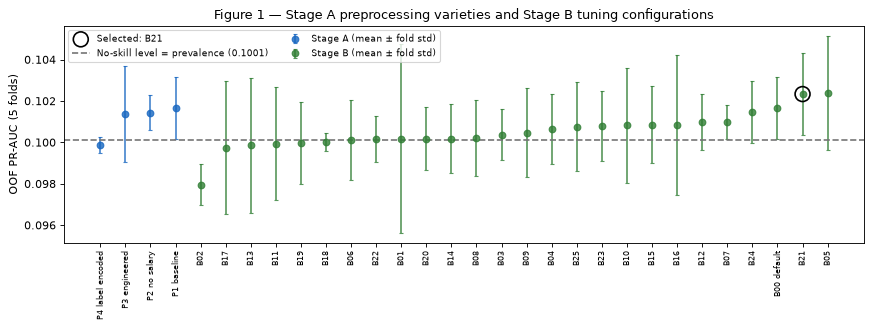

In [13]:
# ------------------------------------------------------------
# FIGURE 1: EVERY VARIETY AND CONFIGURATION vs THE NO-SKILL LEVEL
# ------------------------------------------------------------
# Combine Stage A and Stage B results and sort them for plotting
plot_df = pd.concat([stage_a.assign(stage="Stage A"), tuning.assign(stage="Stage B")])
plot_df = plot_df.sort_values(["stage", "pr_auc_mean"]).reset_index(drop=True)

# Plot the mean PR-AUC ± fold standard deviation for every configuration
fig, ax = plt.subplots(figsize=(11, 4.2))
for stage, color in [("Stage A", "#1565C0"), ("Stage B", "#2E7D32")]:
    part = plot_df[plot_df["stage"] == stage]
    ax.errorbar(part.index, part["pr_auc_mean"], yerr=part["pr_auc_std"], fmt="o",
                color=color, ecolor=color, alpha=0.8, capsize=2, label=f"{stage} (mean ± fold std)")

# Circle the selected configuration
sel_idx = plot_df.index[(plot_df["stage"] == "Stage B") & (plot_df["config"] == SELECTED_CONFIG)][0]
ax.scatter(sel_idx, plot_df.loc[sel_idx, "pr_auc_mean"], s=180, facecolors="none",
           edgecolors="black", linewidths=1.5, label=f"Selected: {SELECTED_CONFIG}", zorder=5)

# Draw the no-skill reference line
ax.axhline(prevalence_dev, color=COLORS["Dummy Prior"], linestyle="--",
           label=f"No-skill level = prevalence ({prevalence_dev:.4f})")

# Label the axes, save the figure (training mode only) and display it
ax.set_xticks(plot_df.index, plot_df["config"].str.replace("_", " "), rotation=90, fontsize=7)
ax.set_ylabel("OOF PR-AUC (5 folds)")
ax.set_title("Figure 1 — Stage A preprocessing varieties and Stage B tuning configurations")
ax.legend(fontsize=8, loc="upper left", ncol=2)
fig.tight_layout()
save_figure(fig, "fig01_tuning_results.png")
plt.show()

**Reading Figure 1.** Every dot is a full 5-fold CV run, and the bars show how much PR-AUC moves between folds. Nearly all varieties and configurations sit on or around the dashed no-skill line, and their error bars overlap it and each other. No preprocessing change or hyperparameter setting produces a clear improvement, which matches the zero-signal finding from the preprocessing notebook.

## 8. Selected configuration: fold metrics and learning curve
The selected configuration's per-fold metrics show how stable it is. Its median best tree count becomes the tree count of the final model (Section 12). The learning curve shows what happens if training continues past early stopping.

In [14]:
# ------------------------------------------------------------
# SELECTED CONFIGURATION: PER-FOLD METRICS AND FEATURE IMPORTANCE
# ------------------------------------------------------------
if RUN_CATBOOST_TRAINING:
    # Re-run the 5-fold CV for the selected configuration
    selected_cv = run_cv(SELECTED_PARAMS, variant=SELECTED_VARIANT, label=SELECTED_CONFIG)
    cv_folds = selected_cv["folds"]
    # Average each feature's importance over the 5 fold models (std = fold-to-fold spread)
    importance_summary = pd.DataFrame({"mean": selected_cv["importance"].mean(axis=1),
                                       "std": selected_cv["importance"].std(axis=1)}).sort_values("mean")
    save_table(cv_folds, "selected_config_fold_metrics.csv")
    save_table(importance_summary.rename_axis("feature").reset_index(), "feature_importance.csv")
else:
    cv_folds = read_evidence("selected_config_fold_metrics.csv")
    importance_summary = read_evidence("feature_importance.csv").set_index("feature")

# The final model's tree count = median best tree count across the 5 folds
FINAL_ITERATIONS = max(1, int(cv_folds["best_iterations"].median()))

# Show the per-fold metrics and the CV mean ± std
display(cv_folds.round(4))
print(f"{SELECTED_CONFIG}: CV PR-AUC {cv_folds['pr_auc'].mean():.4f} ± {cv_folds['pr_auc'].std(ddof=1):.4f} | "
      f"ROC-AUC {cv_folds['roc_auc'].mean():.4f} ± {cv_folds['roc_auc'].std(ddof=1):.4f}")
print(f"Median best tree count across folds -> final model iterations = {FINAL_ITERATIONS}")

,cv_fold,best_iterations,pr_auc,roc_auc,log_loss,brier
0,1,50,0.1009,0.5022,0.3252,0.0901
1,2,1,0.1042,0.5076,0.3252,0.0900
2,3,1,0.0996,0.5001,0.3254,0.0901
3,4,10,0.1038,0.4987,0.3254,0.0901
4,5,14,0.1032,0.5079,0.3253,0.0901


B21: CV PR-AUC 0.1023 ± 0.0020 | ROC-AUC 0.5033 ± 0.0043
Median best tree count across folds -> final model iterations = 10


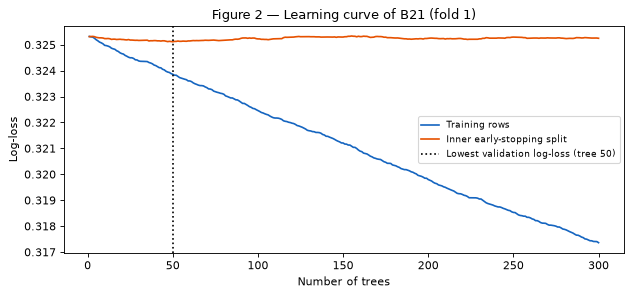

Training log-loss falls from 0.3253 to 0.3174; validation log-loss is lowest at tree 50 (0.3251) and ends at 0.3252.


In [15]:
# ------------------------------------------------------------
# FIGURE 2: LEARNING CURVE (FOLD 1, NO EARLY STOPPING, FOR DIAGNOSIS)
# ------------------------------------------------------------
if RUN_CATBOOST_TRAINING:
    # Trained on fold-1 training rows only; the curve is monitored on the inner
    # early-stopping split. Neither the validation fold nor the holdout is used.
    X_all_sel, cat_cols_sel = build_features(dev, SELECTED_VARIANT)
    train_mask = fold_dev != 1
    X_fit, X_es, y_fit, y_es = train_test_split(X_all_sel[train_mask], y_dev[train_mask],
                                                test_size=INNER_ES_FRACTION,
                                                stratify=y_dev[train_mask], random_state=SEED + 1)
    # Train well past the best tree count (no early stopping) to show what happens afterwards
    curve_params = {**BASE_PARAMS, **SELECTED_PARAMS, "iterations": max(300, 4 * FINAL_ITERATIONS)}
    curve_model = CatBoostClassifier(**curve_params)
    curve_model.fit(Pool(X_fit, y_fit, cat_features=cat_cols_sel),
                    eval_set=Pool(X_es, y_es, cat_features=cat_cols_sel), use_best_model=False)
    # Read the training and validation log-loss after every tree
    history = curve_model.get_evals_result()
    curve = pd.DataFrame({"tree": np.arange(1, len(history["learn"]["Logloss"]) + 1),
                          "train_log_loss": history["learn"]["Logloss"],
                          "validation_log_loss": history["validation"]["Logloss"]})
    save_table(curve, "learning_curve_fold1.csv")
else:
    curve = read_evidence("learning_curve_fold1.csv")

# Find the tree with the lowest validation log-loss
best_it = int(curve["validation_log_loss"].idxmin())

# Plot both curves and mark the best tree
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve["tree"], curve["train_log_loss"], label="Training rows", color="#1565C0")
ax.plot(curve["tree"], curve["validation_log_loss"], label="Inner early-stopping split", color="#E65100")
ax.axvline(curve["tree"][best_it], color="black", linestyle=":",
           label=f"Lowest validation log-loss (tree {curve['tree'][best_it]})")

# Label the axes, save the figure (training mode only) and display it
ax.set_xlabel("Number of trees")
ax.set_ylabel("Log-loss" + (" (class-weighted)" if "auto_class_weights" in SELECTED_PARAMS else ""))
ax.set_title(f"Figure 2 — Learning curve of {SELECTED_CONFIG} (fold 1)")
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "fig02_learning_curve.png")
plt.show()

# Summarise the curve in numbers
print(f"Training log-loss falls from {curve['train_log_loss'].iloc[0]:.4f} to {curve['train_log_loss'].iloc[-1]:.4f}; "
      f"validation log-loss is lowest at tree {curve['tree'][best_it]} ({curve['validation_log_loss'].min():.4f}) "
      f"and ends at {curve['validation_log_loss'].iloc[-1]:.4f}.")

**Reading Figure 2.** Both curves start at the base-rate log-loss, because `boost_from_average` starts every model at about 10%. As trees are added, training log-loss keeps falling: the model memorises noise in the training rows. Validation log-loss barely improves on its starting value, then flattens and rises. This is the classic signature of **overfitting on data without signal**. Early stopping halts training near the validation minimum, so the final model stays small and its probabilities stay close to the base rate.

## 9. Strict nested cross-validation (unbiased estimate for the group comparison)
Stages A and B chose the configuration by looking at the same 5 folds that report its score, so that score is slightly optimistic. Nested CV removes this bias. **Inside each outer fold**:
1. The 4 training folds are split into an inner-training part (85%) and an inner-validation part (15%, stratified).
2. All 26 Stage B candidates are trained on the inner-training part, with early stopping on the inner-validation part.
3. The candidate with the **lowest inner-validation log-loss** wins (the selection metric in `configs/models/catboost.yaml`).
4. The winner is **refit on all 4 training folds** with its early-stopped tree count and predicts the untouched outer fold.

The outer fold never influences selection, early stopping or refitting. The result is one unbiased OOF probability per development employee: 130 inner fits plus 5 outer refits. These predictions are this model's entry in `configs/analysis_registry.yaml` and feed `notebooks/group/02_model_comparison.ipynb`.

In [16]:
# ------------------------------------------------------------
# STRICT NESTED CV (TRAINING MODE) OR VALIDATED SAVED EVIDENCE (SAVED REVIEW)
# ------------------------------------------------------------
def run_nested_cv(candidate_list, variant):
    X_all, cat_cols = build_features(dev, variant)
    oof = np.full(len(dev), np.nan)
    fold_rows, selection_rows = [], []
    params_by_label = dict(candidate_list)
    for k in FOLDS:
        # Outer split: fold k is untouched; the other four folds are the outer training data
        train_mask, valid_mask = fold_dev != k, fold_dev == k
        assert not set(ids_dev[train_mask]) & set(ids_dev[valid_mask]), "ID overlap!"
        X_tr, y_tr = X_all[train_mask], y_dev[train_mask]
        # Inner split, carved only from the outer training data
        X_fit, X_in, y_fit, y_in = train_test_split(
            X_tr, y_tr, test_size=INNER_ES_FRACTION, stratify=y_tr, random_state=SEED + k)
        # Score every candidate on the inner-validation part
        scores = []
        for label, params in candidate_list:
            model = CatBoostClassifier(**BASE_PARAMS, **params)
            model.fit(Pool(X_fit, y_fit, cat_features=cat_cols),
                      eval_set=Pool(X_in, y_in, cat_features=cat_cols),
                      early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True)
            p_in = model.predict_proba(Pool(X_in, cat_features=cat_cols))[:, 1]
            scores.append({"cv_fold": k, "config": label,
                           "inner_log_loss": log_loss(y_in, np.clip(p_in, 1e-7, 1 - 1e-7), labels=[0, 1]),
                           "inner_average_precision": average_precision_score(y_in, p_in),
                           "best_iterations": model.get_best_iteration() + 1})
        scores = pd.DataFrame(scores)
        # Winner = lowest inner log-loss (ties broken by configuration name)
        winner = scores.sort_values(["inner_log_loss", "config"]).iloc[0]
        scores["selected"] = scores["config"] == winner["config"]
        selection_rows.append(scores)
        # Refit the winner on ALL outer training rows with its early-stopped tree count
        refit = CatBoostClassifier(**{**BASE_PARAMS, **params_by_label[winner["config"]],
                                      "iterations": int(winner["best_iterations"])})
        refit.fit(Pool(X_tr, y_tr, cat_features=cat_cols))
        # Predict the untouched outer fold
        prob = refit.predict_proba(Pool(X_all[valid_mask], cat_features=cat_cols))[:, 1]
        oof[valid_mask] = prob
        m = ranking_metrics(y_dev[valid_mask], prob)
        fold_rows.append({"cv_fold": k, "selected_config": winner["config"], "trees": int(winner["best_iterations"]),
                          "average_precision": m["pr_auc"], "roc_auc": m["roc_auc"],
                          "log_loss": m["log_loss"], "brier_score": m["brier"]})
        print(f"Outer fold {k}: winner {winner['config']} ({int(winner['best_iterations'])} trees), "
              f"outer AP {m['pr_auc']:.4f}")
    assert not np.isnan(oof).any()
    return oof, pd.DataFrame(fold_rows), pd.concat(selection_rows, ignore_index=True)


if RUN_CATBOOST_TRAINING:
    # Run the nested CV and save it in the group's OOF / fold / summary evidence format
    t0 = time.time()
    oof_nested, nested_folds, nested_selection = run_nested_cv(candidates, SELECTED_VARIANT)
    nested_oof_table = pd.DataFrame({"Employee_ID": ids_dev, "cv_fold": fold_dev, "y_true": y_dev,
                                     "model_name": "CatBoost Classifier", "y_probability": oof_nested})
    save_table(nested_oof_table, "oof_predictions.csv")
    save_table(nested_folds, "fold_metrics.csv")
    save_table(nested_selection, "nested_candidate_selection.csv")
    # Summary metrics are recomputed from the saved file, so the saved summary always agrees with it
    saved_oof = read_evidence("oof_predictions.csv")
    nested_summary = {
        "model": "CatBoost Classifier", "owner": "IT25100565 (Member 2)",
        "protocol": "strict nested 5-fold: 26 candidates scored on a 15% inner split of each outer-training "
                    "partition; lowest inner log-loss wins; winner refit on all outer-training rows",
        "preprocessing_variant": SELECTED_VARIANT, "candidates": len(candidates),
        "inner_fits": len(candidates) * len(FOLDS), "outer_refits": len(FOLDS),
        "pooled_average_precision": float(average_precision_score(saved_oof.y_true, saved_oof.y_probability)),
        "pooled_roc_auc": float(roc_auc_score(saved_oof.y_true, saved_oof.y_probability)),
        "pooled_brier_score": float(brier_score_loss(saved_oof.y_true, saved_oof.y_probability)),
        "pooled_log_loss": float(log_loss(saved_oof.y_true, saved_oof.y_probability)),
        "cv_ap_mean": float(nested_folds["average_precision"].mean()),
        "cv_ap_sd": float(nested_folds["average_precision"].std(ddof=1)),
        "prevalence": float(prevalence_dev), "rows": int(len(saved_oof)),
        "formal_holdout_accessed": False, "runtime_seconds": round(time.time() - t0, 1),
    }
    (OUTPUT_DIR / "summary_metrics.json").write_text(json.dumps(nested_summary, indent=2), encoding="utf-8")
    oof_nested = saved_oof["y_probability"].to_numpy()
else:
    # Saved review: load the evidence and validate it with the group's own loader when available
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    try:
        from src.evaluation.inputs import load_saved_model_evidence
        saved_oof, nested_folds, nested_summary = load_saved_model_evidence(PROJECT_ROOT, "CatBoost", EVIDENCE_DIR)
        print("Nested OOF validated by src.evaluation.inputs.load_saved_model_evidence "
              "(frozen IDs, folds, targets and summary metrics agree).")
    except ImportError:
        saved_oof = read_evidence("oof_predictions.csv")
        nested_folds = read_evidence("fold_metrics.csv")
        nested_summary = json.loads((EVIDENCE_DIR / "summary_metrics.json").read_text(encoding="utf-8"))
    nested_selection = read_evidence("nested_candidate_selection.csv")
    # Align the saved predictions with the development rows used here
    saved_oof = saved_oof.set_index("Employee_ID").loc[ids_dev].reset_index()
    assert (saved_oof["cv_fold"].to_numpy() == fold_dev).all() and (saved_oof["y_true"].to_numpy() == y_dev).all()
    oof_nested = saved_oof["y_probability"].to_numpy()

# Show which candidate won in each outer fold and the nested scores
display(nested_folds.round(4))
print(f"Nested CV: pooled AP {nested_summary['pooled_average_precision']:.4f} | "
      f"mean fold AP {nested_summary['cv_ap_mean']:.4f} ± {nested_summary['cv_ap_sd']:.4f} | "
      f"pooled ROC-AUC {nested_summary['pooled_roc_auc']:.4f} | prevalence {prevalence_dev:.4f}")
print(f"Non-nested (Stage B) mean fold AP of {SELECTED_CONFIG}: {cv_folds['pr_auc'].mean():.4f} "
      f"-> optimism removed by nesting: {cv_folds['pr_auc'].mean() - nested_summary['cv_ap_mean']:+.4f}")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).
Nested OOF validated by src.evaluation.inputs.load_saved_model_evidence (frozen IDs, folds, targets and summary metrics agree).


,cv_fold,selected_config,trees,average_precision,roc_auc,log_loss,brier_score
0,1,B15,110,0.0975,0.4956,0.3255,0.0901
1,2,B15,77,0.0993,0.4923,0.3254,0.0901
2,3,B18,123,0.1013,0.5061,0.3254,0.0901
3,4,B18,1,0.0999,0.4965,0.3254,0.0901
4,5,B18,102,0.1030,0.5042,0.3254,0.0901


Nested CV: pooled AP 0.0999 | mean fold AP 0.1002 ± 0.0021 | pooled ROC-AUC 0.4996 | prevalence 0.1001
Non-nested (Stage B) mean fold AP of B21: 0.1023 -> optimism removed by nesting: +0.0022


**Reading the nested result.** Different outer folds can pick different winners, which is expected when every candidate is close to no-skill. The nested score is the honest estimate of how this whole tuning procedure performs on unseen employees. The difference from the Stage B score is the optimism that came from selecting on the same folds.

## 10. Comparison with the Dummy baselines
The two mandatory no-skill references are the group's saved `04_baselines.ipynb` outputs in `results/baselines/`, which use exactly the same frozen folds:
- `DummyClassifier(strategy="prior")` gives every employee the training-fold resignation rate (≈ 0.10). It is the no-skill reference for **probabilities and ranking**.
- `DummyClassifier(strategy="most_frequent")` always predicts "stayed". It shows why **90% accuracy is meaningless** here.

CatBoost is represented by its **nested OOF predictions** from Section 9. If the saved baseline files are missing, they are recomputed here on the same folds.

In [17]:
# ------------------------------------------------------------
# LOAD (OR RECOMPUTE) THE DUMMY BASELINE OOF PREDICTIONS
# ------------------------------------------------------------
# Out-of-fold predictions for a Dummy strategy on the frozen folds (fallback only)
def dummy_oof(strategy):
    oof = np.zeros(len(dev))
    for k in FOLDS:
        tr, va = fold_dev != k, fold_dev == k
        # Dummy models ignore the features, so a single constant column is passed
        model = DummyClassifier(strategy=strategy).fit(np.zeros((tr.sum(), 1)), y_dev[tr])
        oof[va] = model.predict_proba(np.zeros((va.sum(), 1)))[:, list(model.classes_).index(1)]
    return oof


# Prefer the group's saved baseline files; align them to the development rows used here
oof_by_model = {"CatBoost": oof_nested}
for name, filename, strategy in [("Dummy Prior", "dummy_prior_oof_predictions.csv", "prior"),
                                 ("Dummy Most Frequent", "dummy_most_frequent_oof_predictions.csv", "most_frequent")]:
    path = BASELINE_DIR / filename
    if path.exists():
        saved = pd.read_csv(path).set_index("Employee_ID").loc[ids_dev]
        assert (saved["cv_fold"].to_numpy() == fold_dev).all() and (saved["y_true"].to_numpy() == y_dev).all()
        oof_by_model[name] = saved["y_probability"].to_numpy()
        print(f"{name:20s} loaded from {rel(path)}")
    else:
        oof_by_model[name] = dummy_oof(strategy)
        print(f"{name:20s} recomputed on the frozen folds ({rel(path)} not found)")

# Pooled PR-AUC of each model (the group's primary metric)
for name, prob in oof_by_model.items():
    print(f"   {name:20s} pooled OOF PR-AUC {average_precision_score(y_dev, prob):.6f}")

Dummy Prior          loaded from results/baselines/dummy_prior_oof_predictions.csv
Dummy Most Frequent  loaded from results/baselines/dummy_most_frequent_oof_predictions.csv
   CatBoost             pooled OOF PR-AUC 0.099860
   Dummy Prior          pooled OOF PR-AUC 0.100085
   Dummy Most Frequent  pooled OOF PR-AUC 0.100100


In [18]:
# ------------------------------------------------------------
# PER-FOLD COMPARISON AND PAIRED TEST
# ------------------------------------------------------------
# PR-AUC computed separately inside each of the 5 folds
def per_fold_pr_auc(oof):
    return np.array([average_precision_score(y_dev[fold_dev == k], oof[fold_dev == k]) for k in FOLDS])


# Per-fold PR-AUC table for CatBoost (nested) and both baselines, plus the CatBoost gain
fold_pr = pd.DataFrame({name: per_fold_pr_auc(prob) for name, prob in oof_by_model.items()},
                       index=pd.Index(FOLDS, name="cv_fold"))
fold_pr["CatBoost − Prior"] = fold_pr["CatBoost"] - fold_pr["Dummy Prior"]
display(fold_pr.round(4))

# Paired t-test: is CatBoost's per-fold PR-AUC different from the Dummy Prior's?
t_stat, t_p = stats.ttest_rel(fold_pr["CatBoost"], fold_pr["Dummy Prior"])
print(f"Paired t-test over 5 folds (CatBoost nested vs Dummy Prior PR-AUC): "
      f"mean difference {fold_pr['CatBoost − Prior'].mean():+.4f}, t = {t_stat:.2f}, p = {t_p:.3f}")

,CatBoost,Dummy Prior,Dummy Most Frequent,CatBoost − Prior
cv_fold,,,,
1,0.0975,0.1001,0.1001,-0.0026
2,0.0993,0.1001,0.1001,-0.0008
3,0.1013,0.1001,0.1001,0.0011
4,0.0999,0.1001,0.1001,-0.0003
5,0.1030,0.1001,0.1001,0.0029


Paired t-test over 5 folds (CatBoost nested vs Dummy Prior PR-AUC): mean difference +0.0001, t = 0.09, p = 0.935


### Decision thresholds
Four cut-offs are compared. Because they are chosen and scored on the same OOF predictions, the threshold metrics are **descriptive**, the same caveat used in the group comparison notebook.

| Threshold | Rule |
| :--- | :--- |
| `0.50` | Default classifier cut-off |
| Base rate | Flag if P(resign) ≥ the development resignation rate (~10%) |
| F1-optimal | The cut-off that maximises F1 on OOF predictions |
| **Top-10% HR budget** | Flag the 10% of employees with the highest risk (OOF 90th percentile). **Operating threshold**, because HR can only hold a limited number of retention conversations |

In [19]:
# ------------------------------------------------------------
# THRESHOLD METRICS ON THE NESTED OOF PREDICTIONS
# ------------------------------------------------------------
# Threshold-based metrics: turn probabilities into yes/no decisions, then score them
def threshold_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": threshold, "flagged_%": 100 * pred.mean(),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "accuracy": accuracy_score(y_true, pred), "tp": tp, "fp": fp, "fn": fn, "tn": tn}


# Compute F1 at every possible threshold to find the F1-optimal cut-off
precision_c, recall_c, thresholds_c = precision_recall_curve(y_dev, oof_nested)
f1_c = 2 * precision_c[:-1] * recall_c[:-1] / np.clip(precision_c[:-1] + recall_c[:-1], 1e-12, None)

# The four candidate thresholds, all derived from development OOF predictions
THRESHOLDS = {
    "0.50 default": 0.5,
    "Base rate": float(prevalence_dev),
    "F1-optimal (OOF)": float(thresholds_c[np.argmax(f1_c)]),
    "Top-10% HR budget (OOF)": float(np.quantile(oof_nested, 0.90)),
}

# The top-10% HR-budget threshold is used as the operating threshold
OPERATING_THRESHOLD_NAME = "Top-10% HR budget (OOF)"
OPERATING_THRESHOLD = THRESHOLDS[OPERATING_THRESHOLD_NAME]

# Score every threshold, then save (training mode only) and show the table
threshold_table = pd.DataFrame([{"rule": name, **threshold_metrics(y_dev, oof_nested, t)}
                                for name, t in THRESHOLDS.items()])
save_table(threshold_table, "threshold_table_oof.csv")
display(threshold_table.round(4))
print(f"Operating threshold: {OPERATING_THRESHOLD_NAME} = {OPERATING_THRESHOLD:.4f}")

,rule,threshold,flagged_%,precision,recall,f1,balanced_accuracy,accuracy,tp,fp,fn,tn
0,0.50 default,0.5000,0.0000,0.0000,0.0000,0.0000,0.5000,0.8999,0,0,8008,71992
1,Base rate,0.1001,47.4100,0.0993,0.4705,0.1641,0.4980,0.5200,3768,34160,4240,37832
2,F1-optimal (OOF),0.0809,99.9925,0.1001,1.0000,0.1820,0.5000,0.1002,8008,71986,0,6
3,Top-10% HR budget (OOF),0.1056,10.0000,0.1003,0.1001,0.1002,0.5001,0.8200,802,7198,7206,64794


Operating threshold: Top-10% HR budget (OOF) = 0.1056


In [20]:
# ------------------------------------------------------------
# COMPARISON TABLE AND BOOTSTRAP 95% CONFIDENCE INTERVALS (DEVELOPMENT OOF)
# ------------------------------------------------------------
# Score each model: ranking metrics, then threshold metrics at 0.50 (plus the operating threshold for CatBoost)
rows = []
for name, prob in oof_by_model.items():
    rules = [("0.50", 0.5)] + ([(OPERATING_THRESHOLD_NAME, OPERATING_THRESHOLD)] if name == "CatBoost" else [])
    for th_name, th in rules:
        rows.append({"model": name, "threshold": th_name,
                     "cv_ap_mean": per_fold_pr_auc(prob).mean(),
                     **{f"oof_{k}": v for k, v in ranking_metrics(y_dev, prob).items()},
                     **{f"oof_{k}": v for k, v in threshold_metrics(y_dev, prob, th).items()
                        if k in ["precision", "recall", "f1", "balanced_accuracy", "accuracy", "flagged_%"]}})
comparison = pd.DataFrame(rows)
save_table(comparison, "model_comparison.csv")
display(comparison.set_index(["model", "threshold"]).round(4).T)

# Resample the development rows 1,000 times and recompute the CatBoost advantage each time
rng = np.random.default_rng(SEED)
pr_diff, roc_diff = [], []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_dev), len(y_dev))
    yb = y_dev[idx]
    pr_diff.append(average_precision_score(yb, oof_nested[idx]) -
                   average_precision_score(yb, oof_by_model["Dummy Prior"][idx]))
    roc_diff.append(roc_auc_score(yb, oof_nested[idx]) - 0.5)

# Point estimate and 95% interval; if the interval contains 0, there is no significant skill
bootstrap = pd.DataFrame({
    "metric": ["PR-AUC: CatBoost − Dummy Prior", "ROC-AUC: CatBoost − 0.5 (no skill)"],
    "point_estimate": [average_precision_score(y_dev, oof_nested) - average_precision_score(y_dev, oof_by_model["Dummy Prior"]),
                       roc_auc_score(y_dev, oof_nested) - 0.5],
    "ci_low_2.5%": [np.percentile(pr_diff, 2.5), np.percentile(roc_diff, 2.5)],
    "ci_high_97.5%": [np.percentile(pr_diff, 97.5), np.percentile(roc_diff, 97.5)],
})
bootstrap["CI contains 0?"] = (bootstrap["ci_low_2.5%"] <= 0) & (bootstrap["ci_high_97.5%"] >= 0)
save_table(bootstrap, "bootstrap_ci_oof.csv")
display(bootstrap.round(4))

model                 CatBoost                         Dummy Prior Dummy Most Frequent
threshold                 0.50 Top-10% HR budget (OOF)        0.50                0.50
cv_ap_mean              0.1002                  0.1002      0.1001              0.1001
oof_pr_auc              0.0999                  0.0999      0.1001              0.1001
oof_roc_auc             0.4996                  0.4996      0.4999              0.5000
oof_log_loss            0.3254                  0.3254      0.3253              1.6134
oof_brier               0.0901                  0.0901      0.0901              0.1001
oof_flagged_%           0.0000                 10.0000      0.0000              0.0000
oof_precision           0.0000                  0.1003      0.0000              0.0000
oof_recall              0.0000                  0.1001      0.0000              0.0000
oof_f1                  0.0000                  0.1002      0.0000              0.0000
oof_balanced_accuracy   0.5000                  0.5001      0.5000              0.5000
oof_accuracy            0.8999                  0.8200      0.8999              0.8999

,metric,point_estimate,ci_low_2.5%,ci_high_97.5%,CI contains 0?
0,PR-AUC: CatBoost − Dummy Prior,-0.0002,-0.0023,0.0024,True
1,ROC-AUC: CatBoost − 0.5 (no skill),-0.0004,-0.0070,0.0063,True


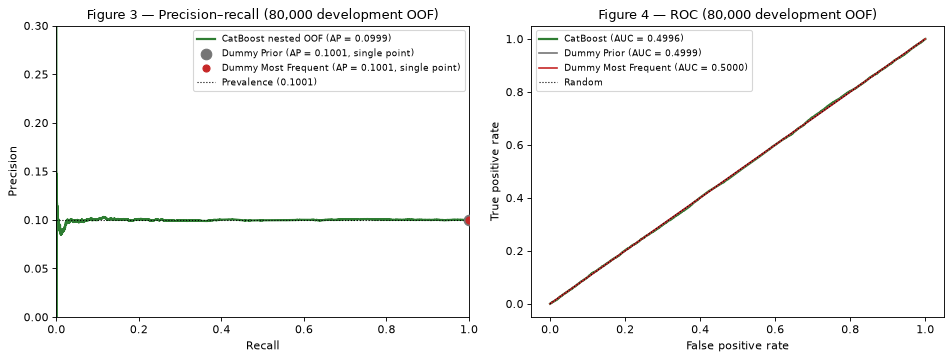

In [21]:
# ------------------------------------------------------------
# FIGURES 3 AND 4: PRECISION-RECALL AND ROC CURVES (NESTED OOF, DEVELOPMENT)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for name, prob in oof_by_model.items():
    ap = average_precision_score(y_dev, prob)
    # Left panel: precision-recall curve
    if name == "CatBoost":
        p, r, _ = precision_recall_curve(y_dev, prob)
        axes[0].plot(r, p, color=COLORS[name], linewidth=2, label=f"CatBoost nested OOF (AP = {ap:.4f})")
    else:
        # A constant score has no curve: its only operating point is "flag everyone".
        axes[0].scatter([1.0], [prevalence_dev], s=90 if name == "Dummy Prior" else 40,
                        color=COLORS[name], zorder=5, label=f"{name} (AP = {ap:.4f}, single point)")
    # Right panel: ROC curve
    fpr, tpr, _ = roc_curve(y_dev, prob)
    axes[1].plot(fpr, tpr, color=COLORS[name], linewidth=2 if name == "CatBoost" else 1.5,
                 label=f"{name} (AUC = {roc_auc_score(y_dev, prob):.4f})")

# Add the no-skill reference lines and label both panels
axes[0].axhline(prevalence_dev, color="black", linestyle=":", linewidth=1,
                label=f"Prevalence ({prevalence_dev:.4f})")
axes[0].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.3),
            title="Figure 3 — Precision–recall (80,000 development OOF)")
axes[1].plot([0, 1], [0, 1], color="black", linestyle=":", linewidth=1, label="Random")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
            title="Figure 4 — ROC (80,000 development OOF)")

# Add legends, save the figure (training mode only) and display it
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "fig03_04_pr_and_roc_curves.png")
plt.show()

**Reading Figures 3 and 4.** The CatBoost precision–recall curve runs along the prevalence line: at every recall level, only about 10% of the employees it flags actually resign, the same as picking at random. The ROC curves lie on the diagonal (AUC ≈ 0.5). A constant score cannot rank anyone, so each Dummy has a single operating point, "flag everyone" (recall 1, precision = prevalence), and lies on the diagonal in the ROC plot.

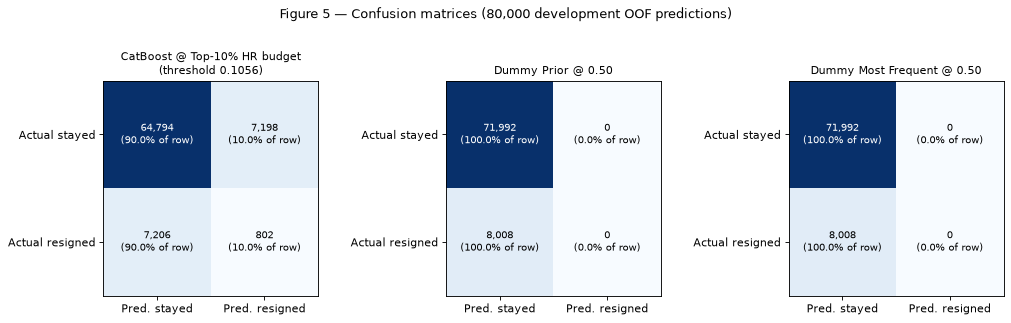

CatBoost @ 0.1056: flags 8,000 employees (10.0%), precision 0.100, recall 0.100
Random selection of the same number: precision ≈ 0.100, recall ≈ 0.100


In [22]:
# ------------------------------------------------------------
# FIGURE 5: CONFUSION MATRICES (NESTED OOF, DEVELOPMENT)
# ------------------------------------------------------------
# One panel per model: (model name, panel title, decision threshold)
panels = [("CatBoost", f"CatBoost @ Top-10% HR budget\n(threshold {OPERATING_THRESHOLD:.4f})", OPERATING_THRESHOLD),
          ("Dummy Prior", "Dummy Prior @ 0.50", 0.5),
          ("Dummy Most Frequent", "Dummy Most Frequent @ 0.50", 0.5)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (name, title, th) in zip(axes, panels):
    # Build the 2x2 confusion matrix and draw it as a heatmap
    cm = confusion_matrix(y_dev, (oof_by_model[name] >= th).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    # Write the count and row percentage inside each cell
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({100 * cm[i, j] / cm[i].sum():.1f}% of row)",
                    ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Pred. stayed", "Pred. resigned"])
    ax.set_yticks([0, 1], ["Actual stayed", "Actual resigned"])
    ax.set_title(title, fontsize=10)

# Add the title, save the figure (training mode only) and display it
fig.suptitle("Figure 5 — Confusion matrices (80,000 development OOF predictions)", y=1.02)
fig.tight_layout()
save_figure(fig, "fig05_confusion_matrices.png")
plt.show()

# Compare CatBoost's flagged group with randomly picking the same number of employees
op = threshold_metrics(y_dev, oof_nested, OPERATING_THRESHOLD)
print(f"CatBoost @ {OPERATING_THRESHOLD:.4f}: flags {op['tp'] + op['fp']:,} employees ({op['flagged_%']:.1f}%), "
      f"precision {op['precision']:.3f}, recall {op['recall']:.3f}")
print(f"Random selection of the same number: precision ≈ {prevalence_dev:.3f}, recall ≈ {op['flagged_%'] / 100:.3f}")

**Reading Figure 5.** Both Dummies predict "stayed" for everyone. They catch 0 resigners yet reach about 90% accuracy, which shows why accuracy is not used to judge models here. For CatBoost at the operating threshold, the printout compares its precision and recall with what randomly picking the same number of employees would achieve.

## 11. Feature importance
Importance (`PredictionValuesChange`) is averaged over the 5 fold models of the selected configuration. Each fold model saw only its own training data. The fold-to-fold spread is shown as error bars.

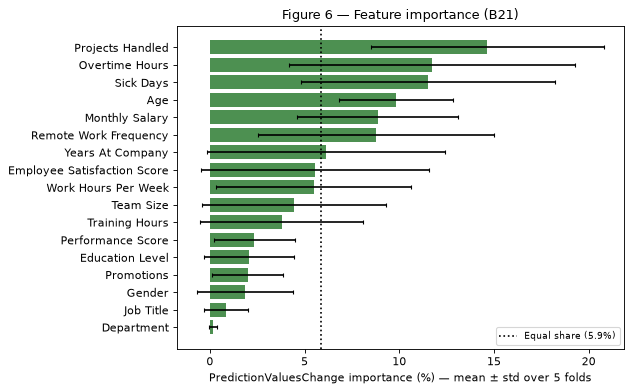

In [23]:
# ------------------------------------------------------------
# FIGURE 6: FEATURE IMPORTANCE ACROSS THE 5 FOLD MODELS
# ------------------------------------------------------------
# Draw a horizontal bar chart with error bars (importance_summary comes from Section 8)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance_summary.index.str.replace("_", " "), importance_summary["mean"],
        xerr=importance_summary["std"], color=COLORS["CatBoost"], alpha=0.85, capsize=2)

# Mark the share each feature would get if all were equally important
ax.axvline(100 / len(importance_summary), color="black", linestyle=":",
           label=f"Equal share ({100 / len(importance_summary):.1f}%)")

# Label the axes, save the figure (training mode only) and display it
ax.set_xlabel("PredictionValuesChange importance (%) — mean ± std over 5 folds")
ax.set_title(f"Figure 6 — Feature importance ({SELECTED_CONFIG})")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_figure(fig, "fig06_feature_importance.png")
plt.show()

**Reading Figure 6.** Importance measures what the model *used*, not whether that use was helpful. The wide error bars and the spread of features around the equal-share line show that the trees split on whichever feature happened to fit the noise in each fold. Sections 9 and 10 showed this produced no predictive gain, so these rankings should **not** be read as real drivers of resignation.

## 12. Final model and the locked-holdout gate
The final model is refit on **all 80,000 development rows** with the selected configuration and the median tree count from Section 8.
- **Training mode:** it is saved to `reruns/<UTC>/model/`. Adopting a run means copying the evidence files into `results/models/catboost/` and the model files into `models/catboost/`.
- **Saved review:** the canonical `.cbm` is loaded. `models/*/*` is git-ignored, so in a fresh clone the same deterministic model is rebuilt **in memory only** (a 1–2 second fit on development rows; nothing is written).

`model_metadata.json` (committed with the evidence) records the feature order, categories, development ranges, parameters, threshold and CV results that the prediction section needs.

In [24]:
# ------------------------------------------------------------
# FINAL MODEL: TRAIN AND SAVE (TRAINING MODE) OR LOAD (SAVED REVIEW)
# ------------------------------------------------------------
# Final model configuration
final_params = {**BASE_PARAMS, **SELECTED_PARAMS, "iterations": FINAL_ITERATIONS}
X_dev_final, cat_cols_final = build_features(dev, SELECTED_VARIANT)
FINAL_FEATURES = list(X_dev_final.columns)


# Helper: fit the final model on all development rows (deterministic: fixed seed and tree count)
def fit_final_model():
    model = CatBoostClassifier(**final_params)
    model.fit(Pool(X_dev_final, y_dev, cat_features=cat_cols_final))
    return model


if RUN_CATBOOST_TRAINING:
    # Train, then save the model and its metadata into the new run folder
    final_model = fit_final_model()
    final_model.save_model(str(OUTPUT_MODEL_DIR / "catboost_resignation_model.cbm"))
    metadata = {
        "model_name": "CatBoost Classifier (Member 2, IT25100565)",
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "model_file": rel(MODEL_FILE), "model_class": "catboost.CatBoostClassifier",
        "task": "binary classification (Resigned: 1 = resigned)",
        "preprocessing_variant": SELECTED_VARIANT, "feature_order": FINAL_FEATURES, "cat_features": cat_cols_final,
        "allowed_categories": {c: ALLOWED_CATEGORIES[c] for c in CATEGORICAL_FEATURES},
        "numeric_ranges_development": {c: {"min": float(dev[c].min()), "max": float(dev[c].max())}
                                       for c in NUMERIC_FEATURES},
        "discrete_numeric_values": {c: data_dictionary["numeric_features"][c]["allowed_values"]
                                    for c in NUMERIC_FEATURES
                                    if "allowed_values" in data_dictionary["numeric_features"][c]},
        "selected_config": SELECTED_CONFIG,
        "params": {k: v for k, v in final_params.items() if k not in ("verbose", "thread_count")},
        "tree_count": int(final_model.tree_count_),
        "selection": {"stage_a_rule": "replace P1 only if per-fold PR-AUC gain is significant (one-sided paired t-test, p < 0.05)",
                      "stage_b_rule": "lowest pooled OOF log-loss among configs within 1 SE of best mean PR-AUC",
                      "nested_rule": "lowest inner-validation log-loss inside each outer fold",
                      "configurations_evaluated": int(len(stage_a) + len(tuning))},
        "threshold": {"name": OPERATING_THRESHOLD_NAME, "value": OPERATING_THRESHOLD,
                      "chosen_on": "development nested OOF predictions only", "all_candidates": THRESHOLDS},
        "base_rate_development": float(prevalence_dev),
        "nested_cv": {k: nested_summary[k] for k in ["pooled_average_precision", "pooled_roc_auc",
                                                     "pooled_brier_score", "cv_ap_mean", "cv_ap_sd"]},
        "formal_holdout_accessed": False,
        "data": {"processed_sha256": data_dictionary["processed_sha256"],
                 "split_registry_sha256": contract["split_registry"]["sha256"]},
        "versions": {"python": platform.python_version(), "catboost": catboost.__version__,
                     "scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    }
    for target in [OUTPUT_MODEL_DIR / "metadata.json", OUTPUT_DIR / "model_metadata.json"]:
        target.write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
    print("Saved model and metadata to", rel(OUTPUT_MODEL_DIR))
else:
    # Saved review: load the committed metadata and the canonical model (or rebuild it in memory)
    metadata = json.loads((EVIDENCE_DIR / "model_metadata.json").read_text(encoding="utf-8"))
    assert metadata["selected_config"] == SELECTED_CONFIG and metadata["tree_count"] == FINAL_ITERATIONS
    if MODEL_FILE.exists():
        final_model = CatBoostClassifier()
        final_model.load_model(str(MODEL_FILE))
        print("Final model loaded from", rel(MODEL_FILE))
    else:
        final_model = fit_final_model()
        print(f"{rel(MODEL_FILE)} not found (models/ is git-ignored): the same deterministic model "
              "was rebuilt in memory; nothing was written.")

print(f"Final model: {final_model.tree_count_} trees, {len(FINAL_FEATURES)} features "
      f"({SELECTED_CONFIG}, {SELECTED_VARIANT}), operating threshold {metadata['threshold']['value']:.4f}")

Final model loaded from models/catboost/catboost_resignation_model.cbm
Final model: 10 trees, 17 features (B21, P1_baseline), operating threshold 0.1056


In [25]:
# ------------------------------------------------------------
# FORMAL HOLDOUT GATE (LOCKED BY DEFAULT)
# ------------------------------------------------------------
if EVALUATE_HOLDOUT:
    # Score the final model and both baselines once on the 20,000 holdout employees
    X_holdout, _ = build_features(holdout, SELECTED_VARIANT)
    y_holdout = holdout[TARGET].to_numpy()
    p_holdout = final_model.predict_proba(Pool(X_holdout, cat_features=cat_cols_final))[:, 1]
    holdout_rows = [{"model": "CatBoost", **ranking_metrics(y_holdout, p_holdout),
                     **threshold_metrics(y_holdout, p_holdout, OPERATING_THRESHOLD)},
                    {"model": "Dummy Prior", **ranking_metrics(y_holdout, np.full(len(y_holdout), prevalence_dev))}]
    holdout_table = pd.DataFrame(holdout_rows)
    save_table(holdout_table, "holdout_evaluation.csv")
    display(holdout_table.round(4))
else:
    print(f"Formal holdout LOCKED: {len(holdout_ids):,} employees not evaluated "
          "(group rule until the final freeze; see docs/FINAL_HOLDOUT_PROTOCOL.md).")

Formal holdout LOCKED: 20,000 employees not evaluated (group rule until the final freeze; see docs/FINAL_HOLDOUT_PROTOCOL.md).


## 13. Manual employee input and prediction
Three ways to enter an employee are provided:
1. **Terminal input (13.1):** the notebook asks for each field one at a time with `input()`, as a command-line program would. Each answer is checked immediately and re-asked if invalid. Pressing Enter accepts the shown default.
2. **Interactive form (13.2):** dropdowns and number boxes (`ipywidgets`).
3. **Dictionary cell (13.3):** edit the values in code and run. This works everywhere.

Every input is validated against the training categories and the development-data ranges. It then goes through the same `build_features` function and `Pool(cat_features=...)` used in training. The output shows the probability, the decision at the operating threshold, the base rate, and the three features that pushed this prediction up or down most (per-row SHAP values).

In [26]:
# ------------------------------------------------------------
# PREDICTION FUNCTIONS (USE THE FINAL MODEL AND ITS METADATA)
# ------------------------------------------------------------
# This cell works on its own: after reopening the notebook you can run it directly,
# with no need for Run All. It reuses the Section 12 model if it is already in memory,
# otherwise it loads the saved model and its metadata from disk (about one second).
import json
from pathlib import Path

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool

if "final_model" in globals() and "metadata" in globals():
    # Run All: use the model and metadata produced in Section 12
    saved_meta, loaded_model = metadata, final_model
    prediction_source = "Section 12 model in memory"
else:
    # Fresh kernel: walk up from the notebook folder to the project root
    _here = Path.cwd().resolve()
    _root = next((p for p in (_here, *_here.parents) if (p / "configs" / "feature_contract.yaml").is_file()), None)
    if _root is None:
        raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
    # Load the committed metadata and the saved model (models/ is git-ignored)
    _model_file = _root / "models" / "catboost" / "catboost_resignation_model.cbm"
    if not _model_file.exists():
        raise FileNotFoundError("models/catboost/catboost_resignation_model.cbm is not on this computer. "
                                "Use Run All once: Section 12 rebuilds the model in memory.")
    saved_meta = json.loads((_root / "results" / "models" / "catboost" / "model_metadata.json")
                            .read_text(encoding="utf-8"))
    loaded_model = CatBoostClassifier()
    loaded_model.load_model(str(_model_file))
    assert loaded_model.tree_count_ == saved_meta["tree_count"], "Saved model and metadata do not match."
    prediction_source = "saved model loaded from disk"

# Feature lists used by the three input methods below (taken from the model's metadata)
PREDICTION_FEATURES = saved_meta["feature_order"]
PREDICTION_NUMERIC = [c for c in PREDICTION_FEATURES if c not in saved_meta["cat_features"]]

# Default employee shown in the terminal prompts (13.1) and the form (13.2)
EMPLOYEE_DEFAULTS = {
    "Department": "IT", "Gender": "Male", "Job_Title": "Developer", "Education_Level": "Bachelor",
    "Age": 28, "Years_At_Company": 3, "Performance_Score": 4, "Monthly_Salary": 6500,
    "Work_Hours_Per_Week": 45, "Projects_Handled": 12, "Overtime_Hours": 8, "Sick_Days": 3,
    "Remote_Work_Frequency": 50, "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
    "Employee_Satisfaction_Score": 3.5,
}


# Check one employee's inputs and return a list of problems (empty list = valid)
def validate_employee(employee):
    problems = []
    # Categories must be one of the labels seen in training
    for c, levels in saved_meta["allowed_categories"].items():
        if employee.get(c) not in levels:
            problems.append(f"{c} must be one of {levels}")
    # Numbers must be present and inside the development-data range
    for c, rng_ in saved_meta["numeric_ranges_development"].items():
        value = employee.get(c)
        if value is None or not np.isfinite(float(value)):
            problems.append(f"{c} is missing")
        elif not rng_["min"] <= float(value) <= rng_["max"]:
            problems.append(f"{c}={value} is outside the training range {rng_['min']:g}–{rng_['max']:g}")
    # Discrete fields (performance, remote %, promotions) must use an allowed value
    for c, allowed in saved_meta["discrete_numeric_values"].items():
        if employee.get(c) is not None and int(employee[c]) not in allowed:
            problems.append(f"{c} must be one of {allowed}")
    return problems


# Validate, predict and explain the resignation risk of one employee
def predict_employee(employee):
    # Reject invalid input instead of scoring it
    problems = validate_employee(employee)
    if problems:
        print("Input rejected:\n - " + "\n - ".join(problems))
        return None
    # Build the features exactly as in training (same variety, column order and cat_features)
    row = pd.DataFrame([employee])
    if "build_features" in globals():
        X_row, _ = build_features(row, saved_meta["preprocessing_variant"])
    elif saved_meta["preprocessing_variant"] == "P1_baseline":
        X_row = row          # P1 uses the 17 contract predictors unchanged
    else:
        raise RuntimeError("This preprocessing variety needs build_features from Section 5: use Run All.")
    X_row = X_row[PREDICTION_FEATURES]
    pool = Pool(X_row, cat_features=saved_meta["cat_features"])
    # Predicted probability of resignation and the operating threshold
    prob = float(loaded_model.predict_proba(pool)[0, 1])
    threshold = saved_meta["threshold"]["value"]
    # Per-row SHAP values: how much each feature pushed this prediction up or down
    shap = loaded_model.get_feature_importance(pool, type="ShapValues")[0, :-1]
    drivers = pd.Series(shap, index=saved_meta["feature_order"]).sort_values(key=np.abs, ascending=False)

    # Print the prediction report
    print("=" * 62)
    print(f"Prediction: {'RESIGNED (flag for HR follow-up)' if prob >= threshold else 'NOT RESIGNED'}")
    print(f"Estimated resignation probability : {100 * prob:.2f}%")
    print(f"Development base rate             : {100 * saved_meta['base_rate_development']:.2f}%")
    print(f"Operating threshold               : {100 * threshold:.2f}%  ({saved_meta['threshold']['name']})")
    base_rate = saved_meta["base_rate_development"]
    print(f"Base-rate threshold {100 * base_rate:.2f}%: {'Yes' if prob >= base_rate else 'No'} | "
          f"In top-10% HR budget ({100 * threshold:.2f}%): {'Yes' if prob >= threshold else 'No'}")
    # The three features with the largest effect on this prediction
    print("Top factors for this employee (SHAP, log-odds):")
    for feature, value in drivers.head(3).items():
        print(f"   {feature:28s} {value:+.4f}  ({'raises' if value > 0 else 'lowers'} risk)")
    print("Note: the model's nested-CV PR-AUC equals the no-skill level, so this score is\n"
          "      close to the base rate and should not drive individual HR decisions.")
    print("=" * 62)
    return prob


print(f"Prediction functions ready ({prediction_source}): {loaded_model.tree_count_} trees, "
      f"{len(saved_meta['feature_order'])} features, threshold {saved_meta['threshold']['value']:.4f}")

Prediction functions ready (Section 12 model in memory): 10 trees, 17 features, threshold 0.1056


### 13.1 Terminal input — type the employee's details at the prompts
Run the cell and answer each question in the input box that appears (in VS Code it appears at the top of the window, in Jupyter under the cell).
- **Categorical fields:** type the option's number or its name.
- **Numeric fields:** type a value inside the range shown.
- **Enter:** accepts the default in brackets.
- **Invalid answers:** the question is asked again; nothing is guessed.

After each prediction you can score another employee. If the notebook is executed without a keyboard (for example, by an automated "run all" tool or the test suite), the cell detects this and replays a recorded example session, so the output is still visible.

In [27]:
# ------------------------------------------------------------
# 13.1 TERMINAL INPUT (input() prompts, validated field by field)
# ------------------------------------------------------------
# Default answer for each field (used when Enter is pressed)
TERMINAL_DEFAULTS = EMPLOYEE_DEFAULTS

# Fields that may have decimals; every other numeric field must be a whole number
FLOAT_FIELDS = {"Employee_Satisfaction_Score", "Monthly_Salary"}


# Ask for one field until a valid answer is typed
def ask_field(field, input_fn):
    label = field.replace("_", " ")
    default = TERMINAL_DEFAULTS[field]
    categories = saved_meta["allowed_categories"].get(field)
    discrete = saved_meta["discrete_numeric_values"].get(field)
    value_range = saved_meta["numeric_ranges_development"].get(field)

    # Build the prompt: numbered options, allowed values, or the valid range
    if categories:
        options = "  ".join(f"{i}={level}" for i, level in enumerate(categories, start=1))
        prompt = f"{label} [{options}] (default {default}): "
    elif discrete:
        prompt = f"{label} {discrete} (default {default}): "
    else:
        prompt = f"{label} ({value_range['min']:g}–{value_range['max']:g}) (default {default}): "

    while True:
        answer = input_fn(prompt).strip()
        # Enter = accept the default
        if answer == "":
            return default
        # Categorical field: accept an option number or the label itself
        if categories:
            if answer.isdigit() and 1 <= int(answer) <= len(categories):
                return categories[int(answer) - 1]
            match = [level for level in categories if level.lower() == answer.lower()]
            if match:
                return match[0]
            print(f"   ! Please type a number 1–{len(categories)} or one of: {', '.join(categories)}")
            continue
        # Numeric field: must be a number ...
        try:
            number = float(answer)
        except ValueError:
            print("   ! Please type a number.")
            continue
        # ... one of the allowed values for discrete fields ...
        if discrete and number not in discrete:
            print(f"   ! Allowed values: {discrete}")
            continue
        # ... inside the training range ...
        if value_range and not value_range["min"] <= number <= value_range["max"]:
            print(f"   ! Must be between {value_range['min']:g} and {value_range['max']:g} (training range).")
            continue
        # ... and a whole number unless decimals are allowed
        if field not in FLOAT_FIELDS and not number.is_integer():
            print("   ! Please type a whole number.")
            continue
        return number if field in FLOAT_FIELDS else int(number)


# Ask for all 17 fields, predict, and offer to score another employee
def terminal_session(input_fn=input):
    while True:
        print("\n--- Enter employee details (press Enter to accept the default) ---")
        employee = {field: ask_field(field, input_fn)
                    for field in [*saved_meta["allowed_categories"], *PREDICTION_NUMERIC]}
        predict_employee(employee)
        again = input_fn("Predict another employee? (y/n) [n]: ").strip().lower()
        if again not in ("y", "yes"):
            print("Terminal session finished.")
            break


def replay(answers):
    # Feeds recorded answers to the prompts and echoes them, like a terminal transcript.
    answer_iter = iter(answers)
    def fake_input(prompt):
        answer = next(answer_iter)
        print(prompt + answer)
        return answer
    return fake_input


# Start the terminal session; if no keyboard is available, replay a recorded example instead
if globals().get("RUN_TERMINAL_INPUT", True):
    try:
        from IPython.core.error import StdinNotImplementedError
    except ImportError:
        StdinNotImplementedError = EOFError
    try:
        terminal_session()
    except (StdinNotImplementedError, EOFError, OSError):
        print("No keyboard input is available in this execution, so a recorded example session is replayed.\n"
              "Run this cell yourself in Jupyter or VS Code to type your own employee.")
        # Example: "IT" typed as option 5, an invalid age (75) re-asked, then mostly defaults.
        recorded = ["5", "Male", "3", "2", "75", "28"] + [""] * 12 + ["n"]
        terminal_session(replay(recorded))


--- Enter employee details (press Enter to accept the default) ---
Prediction: NOT RESIGNED
Estimated resignation probability : 10.05%
Development base rate             : 10.01%
Operating threshold               : 10.56%  (Top-10% HR budget (OOF))
Base-rate threshold 10.01%: Yes | In top-10% HR budget (10.56%): No
Top factors for this employee (SHAP, log-odds):
   Remote_Work_Frequency        +0.0043  (raises risk)
   Sick_Days                    +0.0023  (raises risk)
   Employee_Satisfaction_Score  -0.0016  (lowers risk)
Note: the model's nested-CV PR-AUC equals the no-skill level, so this score is
      close to the base rate and should not drive individual HR decisions.
Terminal session finished.


### 13.2 Interactive form
Fill in the boxes and press **Predict**. The form is a live object in the running Python kernel, so it **cannot be saved inside the notebook file**: after you reopen the notebook, the form area is empty until the cell runs again.

**After reopening the notebook you do not need Run All.** Run two cells:
1. The **PREDICTION FUNCTIONS** cell at the start of Section 13. It loads the saved model in about a second.
2. This form cell.

If the form was saved from an earlier session and now shows an error or a blank box, simply run the two cells again.

In [28]:
# ------------------------------------------------------------
# 13.2 INTERACTIVE FORM (ipywidgets) — fill in and press Predict
# ------------------------------------------------------------
# Needs only the PREDICTION FUNCTIONS cell above (not Run All)
if "predict_employee" not in globals():
    print("First run the 'PREDICTION FUNCTIONS' cell at the start of Section 13, then run this cell again.\n"
          "It loads the saved model in about a second; there is no need for Run All.")
else:
    try:
        # Import the widget library (the form is skipped if it is not installed)
        import ipywidgets as widgets
        from IPython.display import display as ipy_display

        # Ranges, allowed values and default values for the input boxes
        ranges = saved_meta["numeric_ranges_development"]
        discrete = saved_meta["discrete_numeric_values"]
        defaults = EMPLOYEE_DEFAULTS

        # Common label width and box width for a tidy layout
        style = {"description_width": "210px"}
        layout = widgets.Layout(width="440px")

        # Dropdowns for the categorical fields
        inputs = {}
        for c, levels in saved_meta["allowed_categories"].items():
            inputs[c] = widgets.Dropdown(options=levels, value=defaults[c], description=c.replace("_", " "),
                                         style=style, layout=layout)

        # Dropdowns for discrete numbers; bounded number boxes for the rest (out-of-range values are impossible)
        for c in PREDICTION_NUMERIC:
            label = c.replace("_", " ")
            if c in discrete:
                inputs[c] = widgets.Dropdown(options=discrete[c], value=defaults[c], description=label,
                                             style=style, layout=layout)
            elif c == "Employee_Satisfaction_Score":
                inputs[c] = widgets.BoundedFloatText(value=defaults[c], min=ranges[c]["min"], max=ranges[c]["max"],
                                                     step=0.01, description=label, style=style, layout=layout)
            else:
                inputs[c] = widgets.BoundedIntText(value=defaults[c], min=int(ranges[c]["min"]),
                                                   max=int(ranges[c]["max"]), description=label,
                                                   style=style, layout=layout)

        # Predict button and an output area for the result
        button = widgets.Button(description="Predict", button_style="primary", icon="check")
        output = widgets.Output()

        # When Predict is clicked, collect the values and run the prediction
        def on_predict(_):
            output.clear_output()
            with output:
                predict_employee({c: w.value for c, w in inputs.items()})

        # Connect the button and show the form. The printed note is saved in the file;
        # the form itself exists only while the kernel is running.
        button.on_click(on_predict)
        print("If no form appears below (for example after reopening the notebook), run the "
              "PREDICTION FUNCTIONS cell and then this cell.")
        ipy_display(widgets.HTML("<b>CatBoost — employee resignation prediction</b>"),
                    widgets.VBox(list(inputs.values()) + [button, output]))
    except ImportError:
        print("ipywidgets is not installed; use 13.1 or 13.3 (pip install ipywidgets for the form).")


If no form appears below (for example after reopening the notebook), run the PREDICTION FUNCTIONS cell and then this cell.


HTML(value='<b>CatBoost — employee resignation prediction</b>')

### 13.3 Dictionary input

In [29]:
# ------------------------------------------------------------
# 13.3 DICTIONARY INPUT (works everywhere) — edit the values and run
# ------------------------------------------------------------
# Employee details: change any value and re-run the cell
manual_employee = {
    "Department": "IT", "Gender": "Male", "Job_Title": "Developer", "Education_Level": "Bachelor",
    "Age": 28, "Years_At_Company": 3, "Performance_Score": 4, "Monthly_Salary": 6500,
    "Work_Hours_Per_Week": 45, "Projects_Handled": 12, "Overtime_Hours": 8, "Sick_Days": 3,
    "Remote_Work_Frequency": 50, "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
    "Employee_Satisfaction_Score": 3.5,
}

# Predict this employee
_ = predict_employee(manual_employee)

# Validation demo: an impossible input is rejected instead of being scored.
_ = predict_employee({**manual_employee, "Age": 95, "Department": "Space"})

Prediction: NOT RESIGNED
Estimated resignation probability : 10.05%
Development base rate             : 10.01%
Operating threshold               : 10.56%  (Top-10% HR budget (OOF))
Base-rate threshold 10.01%: Yes | In top-10% HR budget (10.56%): No
Top factors for this employee (SHAP, log-odds):
   Remote_Work_Frequency        +0.0043  (raises risk)
   Sick_Days                    +0.0023  (raises risk)
   Employee_Satisfaction_Score  -0.0016  (lowers risk)
Note: the model's nested-CV PR-AUC equals the no-skill level, so this score is
      close to the base rate and should not drive individual HR decisions.
Input rejected:
 - Department must be one of ['Customer Support', 'Engineering', 'Finance', 'HR', 'IT', 'Legal', 'Marketing', 'Operations', 'Sales']
 - Age=95 is outside the training range 22–60


## 14. Conclusion, limitations and improvements
The summary below is generated from the results above, so it always matches the executed run.

In [30]:
# ------------------------------------------------------------
# AUTO-GENERATED RESULTS SUMMARY
# ------------------------------------------------------------
# Pull the numbers needed for the summary from the comparison and bootstrap tables
table = comparison.set_index(["model", "threshold"])
cb05 = table.loc[("CatBoost", "0.50")]
cbop = table.loc[("CatBoost", OPERATING_THRESHOLD_NAME)]
pr_ci, roc_ci = bootstrap.iloc[0], bootstrap.iloc[1]

# CatBoost "beats" the baseline only if the whole confidence interval is above 0
beats = not pr_ci["CI contains 0?"] and pr_ci["point_estimate"] > 0


# Helper: one table row per model
def summary_row(label, key):
    r = table.loc[key]
    return (f"| {label} | {r['oof_pr_auc']:.4f} | {r['cv_ap_mean']:.4f} | {r['oof_roc_auc']:.4f} | "
            f"{r['oof_brier']:.4f} | {r['oof_accuracy']:.4f} | {r['oof_recall']:.4f} |")


# Build the summary text from the computed results
summary_md = "\n".join([
    "| Model (80,000 development OOF) | Pooled PR-AUC | Mean fold PR-AUC | ROC-AUC | Brier | Accuracy @0.50 | Recall @0.50 |",
    "| :--- | ---: | ---: | ---: | ---: | ---: | ---: |",
    summary_row(f"**CatBoost, strict nested** ({SELECTED_VARIANT})", ("CatBoost", "0.50")),
    summary_row("Dummy Prior", ("Dummy Prior", "0.50")),
    summary_row("Dummy Most Frequent", ("Dummy Most Frequent", "0.50")),
    "",
    f"**Stage B (non-nested) mean fold PR-AUC of {SELECTED_CONFIG}:** {cv_folds['pr_auc'].mean():.4f}; "
    f"strict nested: {nested_summary['cv_ap_mean']:.4f} (optimism removed: {cv_folds['pr_auc'].mean() - nested_summary['cv_ap_mean']:+.4f}).",
    "",
    f"**At the top-10% HR-budget threshold** ({OPERATING_THRESHOLD:.4f}), CatBoost flags {cbop['oof_flagged_%']:.1f}% of employees "
    f"with precision **{cbop['oof_precision']:.3f}** and recall **{cbop['oof_recall']:.3f}**; random selection of the same number "
    f"would give precision ≈ {prevalence_dev:.3f} and recall ≈ {cbop['oof_flagged_%'] / 100:.3f}.",
    "",
    f"**Statistical comparison.** PR-AUC difference vs Dummy Prior = {pr_ci['point_estimate']:+.4f} "
    f"(95% bootstrap CI {pr_ci['ci_low_2.5%']:+.4f} to {pr_ci['ci_high_97.5%']:+.4f}); ROC-AUC − 0.5 = {roc_ci['point_estimate']:+.4f} "
    f"(CI {roc_ci['ci_low_2.5%']:+.4f} to {roc_ci['ci_high_97.5%']:+.4f}); paired 5-fold t-test p = {t_p:.3f}.",
    "**Verdict:** " + ("CatBoost shows a statistically significant improvement over the no-skill baseline."
                       if beats else "the confidence interval includes 0, so **CatBoost does not significantly "
                       "outperform the no-skill Dummy baseline** on this dataset."),
])

# Display the summary
display(Markdown(summary_md))

| Model (80,000 development OOF) | Pooled PR-AUC | Mean fold PR-AUC | ROC-AUC | Brier | Accuracy @0.50 | Recall @0.50 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **CatBoost, strict nested** (P1_baseline) | 0.0999 | 0.1002 | 0.4996 | 0.0901 | 0.8999 | 0.0000 |
| Dummy Prior | 0.1001 | 0.1001 | 0.4999 | 0.0901 | 0.8999 | 0.0000 |
| Dummy Most Frequent | 0.1001 | 0.1001 | 0.5000 | 0.1001 | 0.8999 | 0.0000 |

**Stage B (non-nested) mean fold PR-AUC of B21:** 0.1023; strict nested: 0.1002 (optimism removed: +0.0022).

**At the top-10% HR-budget threshold** (0.1056), CatBoost flags 10.0% of employees with precision **0.100** and recall **0.100**; random selection of the same number would give precision ≈ 0.100 and recall ≈ 0.100.

**Statistical comparison.** PR-AUC difference vs Dummy Prior = -0.0002 (95% bootstrap CI -0.0023 to +0.0024); ROC-AUC − 0.5 = -0.0004 (CI -0.0070 to +0.0063); paired 5-fold t-test p = 0.935.
**Verdict:** the confidence interval includes 0, so **CatBoost does not significantly outperform the no-skill Dummy baseline** on this dataset.

### Conclusion
- **Implementation.** A `CatBoostClassifier` was built with native `cat_features` on the group's frozen split and 17-feature contract. Four preprocessing varieties and 26 hyperparameter configurations were compared with leakage-free 5-fold CV (150 fold models). The tuning procedure was then evaluated without selection bias by strict nested CV (130 inner fits + 5 outer refits).
- **Result.** CatBoost's nested PR-AUC and ROC-AUC equal the no-skill level, and the bootstrap confidence interval includes zero. The small edge of the best Stage B configuration is the optimism of choosing the best of many noisy candidates, which is why the group comparison uses the nested predictions.
- **Why.** The preprocessing notebook showed that no feature is related to resignation: all correlations are below 0.01 and all category tests are non-significant. A well-regularised model therefore *should* return probabilities close to the 10% base rate, which is what CatBoost does. Early stopping keeps it from overfitting the noise (Figure 2).
- **Value of the experiment.** It shows that the data, not the algorithm, limits performance. It also demonstrates a validation design that prevents an over-optimistic result: inner early stopping, nested selection, a locked holdout and Dummy baselines.

### Limitations
- The dataset appears to be **synthetically generated with an independent target**: uniform feature distributions, a deterministic salary formula, an identical hire-time timestamp and impossible combinations (hire age under 18). Conclusions cannot be transferred to real employees.
- No real-world drivers of resignation (manager relationship, market pay comparison, commute, career progression history) are available.
- Gender and Age are included because the group contract requires them. A model with real signal would need the subgroup fairness audit in `notebooks/group/04_fairness_analysis.ipynb` before any use.
- With 5 folds, the paired t-test has low power. The bootstrap CI over 80,000 OOF predictions is the stronger evidence. Threshold metrics are descriptive because the thresholds are chosen on the same OOF predictions.
- The formal holdout has not been evaluated (group rule until the final freeze).